# Rossmann Retail + Machine Learning — Fase 1: auditoría de datos

## 1. Objetivo

Comprender la estructura, integridad, cobertura y coherencia comercial de los cuatro
CSV originales. Esta revisión sigue **AGENTS.md**, **requirements.md** y el contexto
de **README.md**, leídos completos el **16 de octubre de 2026**. Los documentos se
identifican por tamaño y SHA-256 al inicio para conservar la trazabilidad.

La metodología de AGENTS.md es **comprender → auditar → investigar → documentar →
decidir → transformar → validar**. En esta ejecución se llega hasta documentar
hallazgos y proponer decisiones pendientes. Las decisiones no se aplican.

| Regla de trabajo | Aplicación en este notebook |
|---|---|
| Auditar antes de transformar | Perfiles, faltantes, claves, cobertura y coherencia comercial. |
| Investigar antes de corregir | Contexto de nulos, anomalías de negocio y extremos por tienda/calendario. |
| Proteger raw | Lectura sin sobrescrituras y comparación de hashes al finalizar. |
| Validar relaciones | Unicidad de Store y merge N:1 temporal con controles antes/después. |
| Documentar decisiones analíticas | Separación entre evidencia, hipótesis y acciones futuras. |

**Alcance de la entrega actual.** Requirements.md contempla auditoría y limpieza
como un entregable amplio, incluido `data/processed/rossmann_clean.csv`. La
instrucción específica de esta fase restringe el trabajo a **auditoría**: la limpieza
y ese archivo quedan pendientes. No se genera ningún dataset processed, no se define
un target y no se avanza al EDA de promociones o al Machine Learning.

No se imputan faltantes, eliminan filas, duplicados ni outliers, reemplazan
categorías o modifican fechas. `Date` permanece tal como fue leída: las Series de
fechas y calendarios auxiliares solo permiten validar formato, cobertura y contexto.
Los subconjuntos, conteos y banderas son diagnósticos y no alteran las tablas originales.

In [1]:
from pathlib import Path
import hashlib
import io
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

get_ipython().run_line_magic('matplotlib', 'inline')
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 35)
pd.set_option('display.width', 150)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.2})

# Permite ejecutar desde la raíz del proyecto o desde notebooks/.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'data' / 'raw' / 'train.csv').is_file())
RAW = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed'
FILES = ['train.csv', 'store.csv', 'test.csv', 'sample_submission.csv']

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def inventory(path):
    return {str(p.relative_to(path)): file_sha256(p)
            for p in sorted(path.rglob('*')) if p.is_file()} if path.exists() else {}

raw_hashes_before = {name: file_sha256(RAW / name) for name in FILES}
processed_before = inventory(PROCESSED)
INSTRUCTIONS = ['AGENTS.md', 'requirements.md', 'README.md']
instruction_hashes_before = {name: file_sha256(ROOT / name) for name in INSTRUCTIONS}
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')
display(pd.DataFrame([
    {'archivo': name, 'bytes': (RAW / name).stat().st_size, 'sha256': raw_hashes_before[name]}
    for name in FILES
]))
display(pd.DataFrame([
    {'instruccion': name, 'bytes': (ROOT / name).stat().st_size,
     'sha256': instruction_hashes_before[name]}
    for name in INSTRUCTIONS
]))

Python 3.13.7 | pandas 3.0.2 | numpy 2.4.4


,archivo,bytes,sha256
0,train.csv,38057952,f6e4597c142d7d909a13d53b68a8e85c00b9a4c7b5ff40...
1,store.csv,45010,f56bd124a2849489e6bbb5c000f5fc9640204355e31647...
2,test.csv,1427425,e75f79972de046d88c2fd55da19df627f5ca654aaf4180...
3,sample_submission.csv,317611,592d892eb07072ddfa3773f13c4822ce5d01981243134c...


,instruccion,bytes,sha256
0,AGENTS.md,8170,b36e923b75b49bdbd64f7cca91085949575bf3868ea50e...
1,requirements.md,2089,6a9ebf8999017b4e6d5653dad57eb47dc119c4321fb3f0...
2,README.md,147,f4ff4eec97442807880b54f1238d665195f8cc0a878a0d...


In [2]:
# Inferencia de tipos uniforme por archivo; no hay conversores ni parse_dates.
train = pd.read_csv(RAW / 'train.csv', low_memory=False)
store = pd.read_csv(RAW / 'store.csv', low_memory=False)
test = pd.read_csv(RAW / 'test.csv', low_memory=False)
sample_submission = pd.read_csv(RAW / 'sample_submission.csv', low_memory=False)
datasets = {'train': train, 'store': store, 'test': test,
            'sample_submission': sample_submission}

def frame_fingerprint(df):
    digest = hashlib.sha256(pd.util.hash_pandas_object(df, index=True).values.tobytes())
    digest.update(repr(tuple(df.columns)).encode())
    digest.update(repr(tuple(map(str, df.dtypes))).encode())
    return digest.hexdigest()

frame_hashes_before = {name: frame_fingerprint(df) for name, df in datasets.items()}

def missing_table(df):
    return pd.DataFrame({'missing': df.isna().sum(),
                         'porcentaje': df.isna().mean().mul(100)})

def frequencies(series):
    counts = series.value_counts(dropna=False)
    return pd.DataFrame({'filas': counts, 'porcentaje': counts.div(len(series)).mul(100)})

def overview(name, df):
    print(f'{name}: shape={df.shape}; columnas={list(df.columns)}')
    display(df.dtypes.rename('tipo').to_frame())
    display(df.head())
    buffer = io.StringIO()
    df.info(buf=buffer, verbose=True, show_counts=True, memory_usage='deep')
    print(buffer.getvalue())
    display(df.describe(include='all').T)

def diagnostic_dates(df):
    # No se asigna el resultado a df['Date']; los errores se cuentan, no se corrigen.
    return pd.to_datetime(df['Date'], format='%Y-%m-%d', errors='coerce')

## 2. Descripción de los datasets

| Tabla | Unidad de observación y función en esta fase |
|---|---|
| `train.csv` | Registro histórico por tienda y día, con ventas, clientes, apertura, promoción y calendario. Es la tabla principal de auditoría. |
| `store.csv` | Una fila de atributos por tienda: tipo, surtido, competencia y participación en Promo2. No contiene un historial de cambios de esos atributos. |
| `test.csv` | Registros por tienda y día de un período posterior; incluye `Id` y no incluye `Sales` ni `Customers`. Se inspecciona su estructura. |
| `sample_submission.csv` | Plantilla de entrega por `Id`, con una columna `Sales` de ejemplo. Sus ceros no son observaciones comerciales. |

Los significados se apoyan en los nombres de campos y la estructura observada.
No se dispone de un diccionario local: se conservan los códigos de `StateHoliday`,
`StoreType`, `Assortment` y `PromoInterval` sin recodificarlos. Las unidades de ventas
y distancia y el significado de cada código deben confirmarse con la documentación
de origen antes de tomar decisiones de limpieza.

### 2.1. Train: perfil general

In [3]:
overview('train', train)

train: shape=(1017209, 9); columnas=['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']


,tipo
Store,int64
DayOfWeek,int64
Date,str
Sales,int64
Customers,int64
Open,int64
Promo,int64
StateHoliday,str
SchoolHoliday,int64


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype
---  ------         --------------    -----
 0   Store          1017209 non-null  int64
 1   DayOfWeek      1017209 non-null  int64
 2   Date           1017209 non-null  str  
 3   Sales          1017209 non-null  int64
 4   Customers      1017209 non-null  int64
 5   Open           1017209 non-null  int64
 6   Promo          1017209 non-null  int64
 7   StateHoliday   1017209 non-null  str  
 8   SchoolHoliday  1017209 non-null  int64
dtypes: int64(7), str(2)
memory usage: 80.5 MB



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Store,1017209.0,NaN,NaN,NaN,558.429727,321.908651,1.0,280.0,558.0,838.0,1115.0
DayOfWeek,1017209.0,NaN,NaN,NaN,3.998341,1.997391,1.0,2.0,4.0,6.0,7.0
Date,1017209,942,2015-07-31,1115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales,1017209.0,NaN,NaN,NaN,5773.818972,3849.926175,0.0,3727.0,5744.0,7856.0,41551.0
Customers,1017209.0,NaN,NaN,NaN,633.145946,464.411734,0.0,405.0,609.0,837.0,7388.0
Open,1017209.0,NaN,NaN,NaN,0.830107,0.375539,0.0,1.0,1.0,1.0,1.0
Promo,1017209.0,NaN,NaN,NaN,0.381515,0.485759,0.0,0.0,0.0,1.0,1.0
StateHoliday,1017209,4,0,986159,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SchoolHoliday,1017209.0,NaN,NaN,NaN,0.178647,0.383056,0.0,0.0,0.0,0.0,1.0


**Interpretación.** Train tiene **1.017.209 filas y 9 columnas**. `Store` identifica
tiendas; no es una magnitud continua. `DayOfWeek`, `Open`, `Promo` y `SchoolHoliday`
son códigos numéricos: sus promedios no sustituyen el análisis de frecuencias.
`Date` se mantiene como texto y `StateHoliday` conserva sus etiquetas originales.

### 2.2. Store: perfil general

In [4]:
overview('store', store)

store: shape=(1115, 10); columnas=['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


,tipo
Store,int64
StoreType,str
Assortment,str
CompetitionDistance,float64
CompetitionOpenSinceMonth,float64
CompetitionOpenSinceYear,float64
Promo2,int64
Promo2SinceWeek,float64
Promo2SinceYear,float64
PromoInterval,str


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   str    
 2   Assortment                 1115 non-null   str    
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    str    
dtypes: float64(5), int64(2), str(3)
memory usage: 98.0 KB



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Store,1115.0,NaN,NaN,NaN,558.0,322.01708,1.0,279.5,558.0,836.5,1115.0
StoreType,1115,4,a,602,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Assortment,1115,3,a,593,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CompetitionDistance,1112.0,NaN,NaN,NaN,5404.901079,7663.17472,20.0,717.5,2325.0,6882.5,75860.0
CompetitionOpenSinceMonth,761.0,NaN,NaN,NaN,7.224704,3.212348,1.0,4.0,8.0,10.0,12.0
CompetitionOpenSinceYear,761.0,NaN,NaN,NaN,2008.668857,6.195983,1900.0,2006.0,2010.0,2013.0,2015.0
Promo2,1115.0,NaN,NaN,NaN,0.512108,0.500078,0.0,0.0,1.0,1.0,1.0
Promo2SinceWeek,571.0,NaN,NaN,NaN,23.595447,14.141984,1.0,13.0,22.0,37.0,50.0
Promo2SinceYear,571.0,NaN,NaN,NaN,2011.763573,1.674935,2009.0,2011.0,2012.0,2013.0,2015.0
PromoInterval,571,3,"Jan,Apr,Jul,Oct",335,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Interpretación.** Store tiene **1.115 filas y 10 columnas**. Los campos de mes,
año y semana con faltantes se infieren como `float64`: esto no implica que las
fracciones sean válidas. Su integridad se comprueba más adelante sin convertirlos.

### 2.3. Test: estructura y diferencias respecto de train

In [5]:
overview('test', test)
display(missing_table(test))
print('Columnas solo en train:', sorted(set(train.columns) - set(test.columns)))
print('Columnas solo en test:', sorted(set(test.columns) - set(train.columns)))
common = [c for c in train.columns if c in test.columns]
display(pd.DataFrame({'train_dtype': train[common].dtypes.astype(str),
                      'test_dtype': test[common].dtypes.astype(str)}))
open_unknown = test['Open'].isna()
display(test.loc[open_unknown])
print('Metadatos de las tiendas con Open desconocido en test:')
display(store.loc[store['Store'].isin(test.loc[open_unknown, 'Store'])])
print('Tiendas test:', test['Store'].nunique())
print('Tiendas test fuera de train:', sorted(set(test['Store']) - set(train['Store'])))
print('Tiendas test fuera de store:', sorted(set(test['Store']) - set(store['Store'])))

test: shape=(41088, 8); columnas=['Id', 'Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']


,tipo
Id,int64
Store,int64
DayOfWeek,int64
Date,str
Open,float64
Promo,int64
StateHoliday,str
SchoolHoliday,int64


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0


<class 'pandas.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             41088 non-null  int64  
 1   Store          41088 non-null  int64  
 2   DayOfWeek      41088 non-null  int64  
 3   Date           41088 non-null  str    
 4   Open           41077 non-null  float64
 5   Promo          41088 non-null  int64  
 6   StateHoliday   41088 non-null  str    
 7   SchoolHoliday  41088 non-null  int64  
dtypes: float64(1), int64(5), str(2)
memory usage: 2.9 MB



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,41088.0,NaN,NaN,NaN,20544.5,11861.228267,1.0,10272.75,20544.5,30816.25,41088.0
Store,41088.0,NaN,NaN,NaN,555.899533,320.274496,1.0,279.75,553.5,832.25,1115.0
DayOfWeek,41088.0,NaN,NaN,NaN,3.979167,2.015481,1.0,2.0,4.0,6.0,7.0
Date,41088,48,2015-09-17,856,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Open,41077.0,NaN,NaN,NaN,0.854322,0.352787,0.0,1.0,1.0,1.0,1.0
Promo,41088.0,NaN,NaN,NaN,0.395833,0.489035,0.0,0.0,0.0,1.0,1.0
StateHoliday,41088,2,0,40908,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SchoolHoliday,41088.0,NaN,NaN,NaN,0.443487,0.496802,0.0,0.0,0.0,1.0,1.0


...

,train_dtype,test_dtype
Store,int64,int64
DayOfWeek,int64,int64
Date,str,str
Open,int64,float64
Promo,int64,int64
StateHoliday,str,str
SchoolHoliday,int64,int64


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
479,480,622,4,2015-09-17,NaN,1,0,0
1335,1336,622,3,2015-09-16,NaN,1,0,0
2191,2192,622,2,2015-09-15,NaN,1,0,0
3047,3048,622,1,2015-09-14,NaN,1,0,0
4759,4760,622,6,2015-09-12,NaN,0,0,0
5615,5616,622,5,2015-09-11,NaN,0,0,0
6471,6472,622,4,2015-09-10,NaN,0,0,0
7327,7328,622,3,2015-09-09,NaN,0,0,0
8183,8184,622,2,2015-09-08,NaN,0,0,0
9039,9040,622,1,2015-09-07,NaN,0,0,0


Metadatos de las tiendas con Open desconocido en test:


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
621,622,a,c,NaN,NaN,NaN,0,NaN,NaN,NaN


Tiendas test: 856
Tiendas test fuera de train: []
Tiendas test fuera de store: []


**Interpretación.** Test tiene **41.088 filas, 8 columnas y 856 tiendas**, todas
presentes en train y store. Agrega `Id` y omite `Sales` y `Customers`. Hay **11
faltantes en `Open`, todos de Store 622**, entre el 5 y el 17 de septiembre de
2015; el tipo inferido de `Open` difiere de train por esos faltantes.

Store 622 también carece de los tres datos de competencia en store. Esa coincidencia
localiza la información desconocida, pero no demuestra una causa común ni permite
deducir su apertura. Se conserva cada faltante y se deja pendiente la consulta al origen.

### 2.4. Sample submission: función de la plantilla

In [6]:
overview('sample_submission', sample_submission)
display(missing_table(sample_submission))
display(pd.DataFrame([{
    'filas_plantilla': len(sample_submission),
    'filas_test': len(test),
    'Id_missing': int(sample_submission['Id'].isna().sum()),
    'Id_duplicados': int(sample_submission['Id'].duplicated().sum()),
    'mismos_Id': set(sample_submission['Id']) == set(test['Id']),
    'mismo_orden_Id': sample_submission['Id'].equals(test['Id']),
    'Sales_solo_cero': bool(sample_submission['Sales'].eq(0).all())
}]))

sample_submission: shape=(41088, 2); columnas=['Id', 'Sales']


,tipo
Id,int64
Sales,int64


,Id,Sales
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0


<class 'pandas.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Id      41088 non-null  int64
 1   Sales   41088 non-null  int64
dtypes: int64(2)
memory usage: 642.1 KB



,count,mean,std,min,25%,50%,75%,max
Id,41088.0,20544.5,11861.228267,1.0,10272.75,20544.5,30816.25,41088.0
Sales,41088.0,0.0,0.000000,0.0,0.00,0.0,0.00,0.0


,missing,porcentaje
Id,0,0.0
Sales,0,0.0


,filas_plantilla,filas_test,Id_missing,Id_duplicados,mismos_Id,mismo_orden_Id,Sales_solo_cero
0,41088,41088,0,0,True,True,True


**Interpretación.** La plantilla contiene **41.088 Id únicos**, alineados con test,
y valores de ejemplo `Sales = 0`. Solo documenta el formato de entrega; no se usa
para inferir ventas ni para definir todavía un target.

In [7]:
train_dates = diagnostic_dates(train)
test_dates = diagnostic_dates(test)
date_summary = pd.DataFrame([
    {'dataset': name, 'min_fecha': dates.min(), 'max_fecha': dates.max(),
     'fechas_unicas': dates.nunique(), 'Date_missing': int(df['Date'].isna().sum()),
     'fechas_no_interpretables': int((df['Date'].notna() & dates.isna()).sum()),
     'formato_no_ISO': int((~df['Date'].str.fullmatch(r'\d{4}-\d{2}-\d{2}', na=False)).sum()),
     'DayOfWeek_inconsistente': int((dates.notna() & dates.dt.dayofweek.add(1).ne(df['DayOfWeek'])).sum())}
    for name, df, dates in [('train', train, train_dates), ('test', test, test_dates)]
]).set_index('dataset')
display(date_summary)
print('Días compartidos entre train y test:', len(set(train['Date']) & set(test['Date'])))

,min_fecha,max_fecha,fechas_unicas,Date_missing,fechas_no_interpretables,formato_no_ISO,DayOfWeek_inconsistente
dataset,,,,,,,
train,2013-01-01,2015-07-31,942,0,0,0,0
test,2015-08-01,2015-09-17,48,0,0,0,0


Días compartidos entre train y test: 0


**Interpretación temporal.** Train abarca **2013-01-01 a 2015-07-31 (942 fechas)**
y test **2015-08-01 a 2015-09-17 (48 fechas)**, sin solapamiento. No hay fechas
no interpretables, formatos distintos del ISO esperado ni desacuerdos con
`DayOfWeek` bajo la convención lunes=1 a domingo=7. Son validaciones sobre Series
auxiliares; no se reemplazó ni convirtió la columna `Date` de ninguna tabla.

## 3. Auditoría de train

### 3.1. Completitud, duplicados y cardinalidad

In [8]:
print('Filas:', len(train), '| Columnas:', train.shape[1])
print('Tiendas:', train['Store'].nunique(), '| Duplicados completos:', train.duplicated().sum())
display(missing_table(train))
display(pd.DataFrame({
    'tipo': train.dtypes.astype(str),
    'valores_distintos_sin_missing': train.nunique(dropna=True),
    'valores_distintos_con_missing': train.nunique(dropna=False)
}))

Filas: 1017209 | Columnas: 9
Tiendas: 1115 | Duplicados completos: 0


,missing,porcentaje
Store,0,0.0
DayOfWeek,0,0.0
Date,0,0.0
Sales,0,0.0
Customers,0,0.0
Open,0,0.0
Promo,0,0.0
StateHoliday,0,0.0
SchoolHoliday,0,0.0


,tipo,valores_distintos_sin_missing,valores_distintos_con_missing
Store,int64,1115,1115
DayOfWeek,int64,7,7
Date,str,942,942
Sales,int64,21734,21734
Customers,int64,4086,4086
Open,int64,2,2
Promo,int64,2,2
StateHoliday,str,4,4
SchoolHoliday,int64,2,2


**Hallazgo.** No hay valores faltantes reconocidos por el lector CSV ni duplicados
completos en train. Hay **1.115 tiendas**. La ausencia de nulos de celda no prueba
que el panel tenga todos los días de cada tienda: eso se audita por separado.

In [9]:
train_categorical = ['DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']
for col in train_categorical:
    print(f'Frecuencias: {col}')
    display(frequencies(train[col]))

domains_train = {
    'DayOfWeek': set(range(1, 8)), 'Open': {0, 1}, 'Promo': {0, 1},
    'StateHoliday': {'0', 'a', 'b', 'c'}, 'SchoolHoliday': {0, 1}
}
display(pd.DataFrame([
    {'columna': col, 'fuera_dominio_de_control': int((train[col].notna() & ~train[col].isin(domain)).sum())}
    for col, domain in domains_train.items()
]))
print('Tipos Python observados en StateHoliday:', train['StateHoliday'].map(type).value_counts().to_dict())
display(pd.DataFrame([
    {'variable': col, 'negativos': int(train[col].lt(0).sum()),
     'no_enteros': int(train[col].mod(1).ne(0).sum()), 'ceros': int(train[col].eq(0).sum())}
    for col in ['Sales', 'Customers']
]))

Frecuencias: DayOfWeek


,filas,porcentaje
DayOfWeek,,
5,145845,14.337761
4,145845,14.337761
3,145665,14.320066
2,145664,14.319968
1,144730,14.228148
7,144730,14.228148
6,144730,14.228148


Frecuencias: Open


,filas,porcentaje
Open,,
1,844392,83.010669
0,172817,16.989331


Frecuencias: Promo


...

Frecuencias: SchoolHoliday


,filas,porcentaje
SchoolHoliday,,
0,835488,82.135333
1,181721,17.864667


,columna,fuera_dominio_de_control
0,DayOfWeek,0
1,Open,0
2,Promo,0
3,StateHoliday,0
4,SchoolHoliday,0


Tipos Python observados en StateHoliday: {<class 'str'>: 1017209}


,variable,negativos,no_enteros,ceros
0,Sales,0,0,172871
1,Customers,0,0,172869


**Interpretación.** Los dominios observados son coherentes con esos códigos de
control; no se detectan ventas/clientes negativos o fraccionarios. `StateHoliday`
se lee uniformemente como texto con `low_memory=False`: `'0'` es una categoría,
no un missing. Se observan 172.817 cierres y 388.080 filas con `Promo = 1`.
La distribución de `Store` se revisa como cobertura del identificador, sin
tratar 1.115 códigos como categorías comerciales con orden numérico.

### 3.2. Cobertura de tiendas y fechas: ausencia de filas frente a missing de celda

In [10]:
store_coverage = train.groupby('Store').agg(
    filas=('Date', 'size'), fechas_unicas=('Date', 'nunique'),
    primera_fecha=('Date', 'min'), ultima_fecha=('Date', 'max'))
display(store_coverage.groupby(['filas', 'fechas_unicas', 'primera_fecha', 'ultima_fecha'])
        .size().rename('tiendas').to_frame())

# Calendario de referencia para detectar ausencias: no agrega filas a train.
calendar = pd.date_range(train_dates.min(), train_dates.max(), freq='D')
date_coverage = train.groupby('Date')['Store'].nunique().rename('tiendas_presentes')
display(date_coverage.value_counts().rename_axis('tiendas_presentes').rename('dias').to_frame())
print('Fechas completas ausentes del histórico:',
      len(calendar.difference(pd.DatetimeIndex(train_dates))))

# Identificar todos los intervalos ausentes sin fijar de antemano tiendas o fechas.
indices_by_store = train.groupby('Store').groups
gap_records = []
for store_id in store['Store'].unique():
    observed_index = indices_by_store.get(store_id, [])
    observed_dates = pd.DatetimeIndex(train_dates.loc[observed_index])
    absent_dates = pd.Series(calendar.difference(observed_dates))
    if absent_dates.empty:
        continue
    block = absent_dates.diff().ne(pd.Timedelta(days=1)).cumsum()
    for interval in absent_dates.groupby(block).agg(['min', 'max', 'size']).itertuples(index=False):
        gap_records.append({'Store': store_id, 'inicio_ausencia': interval.min,
                            'fin_ausencia': interval.max, 'dias_ausentes': interval.size})
gap_detail = pd.DataFrame(gap_records,
                          columns=['Store', 'inicio_ausencia', 'fin_ausencia', 'dias_ausentes'])
print('Intervalos de ausencia agrupados:')
display(gap_detail.groupby(['inicio_ausencia', 'fin_ausencia', 'dias_ausentes'])
        .agg(tiendas=('Store', 'nunique')))
print('Ejemplos de tiendas afectadas:')
display(gap_detail.head(10))

expected_pairs = store['Store'].nunique() * len(calendar)
observed_pairs = train.groupby(['Store', 'Date'], dropna=False).ngroups
print('Combinaciones de una grilla rectangular:', expected_pairs)
print('Combinaciones observadas:', observed_pairs)
print('Combinaciones ausentes frente a esa referencia:', expected_pairs - observed_pairs)
print('Días ausentes contados por intervalos:', gap_detail['dias_ausentes'].sum())
print('Tiendas históricas fuera de store:', sorted(set(train['Store']) - set(store['Store'])))

,,,,tiendas
filas,fechas_unicas,primera_fecha,ultima_fecha,
758,758,2013-01-01,2015-07-31,180
941,941,2013-01-02,2015-07-31,1
942,942,2013-01-01,2015-07-31,934


,dias
tiendas_presentes,
1115,757
935,184
1114,1


Fechas completas ausentes del histórico: 0
Intervalos de ausencia agrupados:


,,,tiendas
inicio_ausencia,fin_ausencia,dias_ausentes,
2013-01-01,2013-01-01,1,1
2014-07-01,2014-12-31,184,180


Ejemplos de tiendas afectadas:


,Store,inicio_ausencia,fin_ausencia,dias_ausentes
0,13,2014-07-01,2014-12-31,184
1,20,2014-07-01,2014-12-31,184
2,22,2014-07-01,2014-12-31,184
3,32,2014-07-01,2014-12-31,184
4,36,2014-07-01,2014-12-31,184
5,41,2014-07-01,2014-12-31,184
6,46,2014-07-01,2014-12-31,184
7,51,2014-07-01,2014-12-31,184
8,52,2014-07-01,2014-12-31,184
9,58,2014-07-01,2014-12-31,184


Combinaciones de una grilla rectangular: 1050330
Combinaciones observadas: 1017209
Combinaciones ausentes frente a esa referencia: 33121
Días ausentes contados por intervalos: 33121
Tiendas históricas fuera de store: []


**Hallazgo de cobertura.** 934 tiendas tienen 942 registros; **180 tienen 758** y
no aparecen entre **2014-07-01 y 2014-12-31** (184 días). Store **988** tiene 941
y falta el **2013-01-01**. Los intervalos se detectaron para todas las tiendas,
sin seleccionar previamente esos casos. No faltan fechas enteras en el histórico.

Los huecos suman **33.121 combinaciones** frente a una referencia rectangular de
1.050.330 tienda–día. Esto no equivale a ventas cero ni a tiendas cerradas: podría
responder a la extracción o cobertura de origen. Se requiere documentación para
decidir si esa grilla completa era realmente esperada. No se agregan registros ni
se interpreta ausencia como cierre.

## 4. Auditoría de store

### 4.1. Completitud, categorías y dominios

In [11]:
print('Filas:', len(store), '| Tiendas:', store['Store'].nunique())
print('Duplicados completos:', store.duplicated().sum())
display(missing_table(store))
for col in ['StoreType', 'Assortment', 'Promo2', 'PromoInterval']:
    print(f'Frecuencias: {col}')
    display(frequencies(store[col]))
display(pd.crosstab(store['StoreType'], store['Assortment'], margins=True))

store_domains = {'StoreType': {'a', 'b', 'c', 'd'}, 'Assortment': {'a', 'b', 'c'}, 'Promo2': {0, 1}}
display(pd.DataFrame([
    {'variable': col, 'fuera_dominio_de_control': int((store[col].notna() & ~store[col].isin(domain)).sum())}
    for col, domain in store_domains.items()
]))
calendar_domains = [('CompetitionOpenSinceMonth', 1, 12),
                    ('CompetitionOpenSinceYear', 1, 9999),
                    ('Promo2SinceWeek', 1, 53), ('Promo2SinceYear', 1, 9999)]
display(pd.DataFrame([
    {'variable': col,
     'fuera_rango_no_nulos': int((store[col].notna() & ~store[col].between(lo, hi)).sum()),
     'no_enteros_no_nulos': int((store[col].notna() & store[col].mod(1).ne(0)).sum())}
    for col, lo, hi in calendar_domains
]))
print('CompetitionDistance negativa o cero:', int(store['CompetitionDistance'].le(0).sum()))

Filas: 1115 | Tiendas: 1115
Duplicados completos: 0


,missing,porcentaje
Store,0,0.000000
StoreType,0,0.000000
Assortment,0,0.000000
CompetitionDistance,3,0.269058
CompetitionOpenSinceMonth,354,31.748879
CompetitionOpenSinceYear,354,31.748879
Promo2,0,0.000000
Promo2SinceWeek,544,48.789238
Promo2SinceYear,544,48.789238
PromoInterval,544,48.789238


Frecuencias: StoreType


,filas,porcentaje
StoreType,,
a,602,53.991031
d,348,31.210762
c,148,13.273543
b,17,1.524664


Frecuencias: Assortment


...

,filas,porcentaje
PromoInterval,,
NaN,544,48.789238
"Jan,Apr,Jul,Oct",335,30.044843
"Feb,May,Aug,Nov",130,11.659193
"Mar,Jun,Sept,Dec",106,9.506726


Assortment,a,b,c,All
StoreType,,,,
a,381,0,221,602
b,7,9,1,17
c,77,0,71,148
d,128,0,220,348
All,593,9,513,1115


,variable,fuera_dominio_de_control
0,StoreType,0
1,Assortment,0
2,Promo2,0


,variable,fuera_rango_no_nulos,no_enteros_no_nulos
0,CompetitionOpenSinceMonth,0,0
1,CompetitionOpenSinceYear,0,0
2,Promo2SinceWeek,0,0
3,Promo2SinceYear,0,0


CompetitionDistance negativa o cero: 0


**Interpretación.** Las categorías predominantes son `StoreType = a` (602 tiendas)
y `Assortment = a` (593); las categorías `b` son escasas (17 y 9 respectivamente),
sin que eso constituya un error. Meses, semanas y años informados son enteros
dentro de los rangos de control, y las distancias informadas son positivas.
El control de rango de año es amplio: no demuestra plausibilidad histórica.

### 4.2. Promo2: faltantes condicionados a participación

In [12]:
promo2_cols = ['Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']
promo2_missing = []
for participation, group in store.groupby('Promo2', dropna=False):
    for col in promo2_cols:
        promo2_missing.append({'Promo2': participation, 'variable': col, 'tiendas': len(group),
                               'missing': int(group[col].isna().sum()),
                               'missing_pct': group[col].isna().mean() * 100})
display(pd.DataFrame(promo2_missing))
display(store[promo2_cols].isna().value_counts(dropna=False).rename('tiendas').to_frame())

promo2_rules = {
    'Promo2=0 con algun detalle informado': store['Promo2'].eq(0) & store[promo2_cols].notna().any(axis=1),
    'Promo2=1 con algun detalle faltante': store['Promo2'].eq(1) & store[promo2_cols].isna().any(axis=1)
}
for label, mask in promo2_rules.items():
    print(label, ':', int(mask.sum()))
    display(store.loc[mask].head(5))
for col in promo2_cols:
    print(f'Distribución original: {col}')
    display(frequencies(store[col]))
display(store.loc[store['Promo2'].eq(0)].head(3))
display(store.loc[store['Promo2'].eq(1)].head(3))

,Promo2,variable,tiendas,missing,missing_pct
0,0,Promo2SinceWeek,544,544,100.0
1,0,Promo2SinceYear,544,544,100.0
2,0,PromoInterval,544,544,100.0
3,1,Promo2SinceWeek,571,0,0.0
4,1,Promo2SinceYear,571,0,0.0
5,1,PromoInterval,571,0,0.0


,,,tiendas
Promo2SinceWeek,Promo2SinceYear,PromoInterval,
False,False,False,571
True,True,True,544


Promo2=0 con algun detalle informado : 0


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval


Promo2=1 con algun detalle faltante : 0


...

,filas,porcentaje
Promo2SinceYear,,
NaN,544,48.789238
2011.0,128,11.479821
2013.0,120,10.762332
2014.0,95,8.520179
2012.0,81,7.264574
2009.0,73,6.547085
2010.0,64,5.739910
2015.0,10,0.896861


Distribución original: PromoInterval


,filas,porcentaje
PromoInterval,,
NaN,544,48.789238
"Jan,Apr,Jul,Oct",335,30.044843
"Feb,May,Aug,Nov",130,11.659193
"Mar,Jun,Sept,Dec",106,9.506726


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
10,11,a,c,960.0,11.0,2011.0,1,1.0,2012.0,"Jan,Apr,Jul,Oct"


**Hallazgo: faltantes compatibles con estructura.** Las **544 tiendas con Promo2 = 0**
tienen vacíos los tres detalles; las **571 con Promo2 = 1** tienen los tres
informados. No hay contradicciones entre participación y disponibilidad de detalles.
La evidencia es consistente con «no aplica» para no participantes, pendiente de
confirmar con el diccionario. Imputar una semana o año a todas las tiendas
inventaría una participación que no consta. Los nulos se conservan.

`PromoInterval` conserva tres etiquetas informadas y sus abreviaturas originales,
incluyendo `Sept`; no se dividen ni reemplazan los textos.

### 4.3. Competencia: faltantes conjuntos y límites de interpretación

In [13]:
competition_cols = ['CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear']
display(store[competition_cols].isna().value_counts(dropna=False).rename('tiendas').to_frame())
display(pd.crosstab(store['CompetitionDistance'].isna(),
                    store['CompetitionOpenSinceYear'].isna(),
                    rownames=['distancia_missing'], colnames=['año_missing'], margins=True))
print('Mes y año con distinta condición de missing:',
      int(store['CompetitionOpenSinceMonth'].isna().ne(store['CompetitionOpenSinceYear'].isna()).sum()))
print('Porcentaje de faltantes de competencia dentro de cada StoreType:')
display(store.groupby('StoreType')[competition_cols].agg(lambda s: s.isna().mean() * 100))
display(store.loc[store['CompetitionDistance'].isna()])
display(store.loc[store['CompetitionDistance'].notna() & store['CompetitionOpenSinceYear'].isna()].head(5))
display(store[competition_cols].describe(percentiles=[.01, .25, .5, .75, .95, .99]).T)
print('Años de apertura de competencia:')
display(frequencies(store['CompetitionOpenSinceYear']))
print('Meses de apertura de competencia:')
display(frequencies(store['CompetitionOpenSinceMonth']))

tiendas
CompetitionDistance CompetitionOpenSinceMonth CompetitionOpenSinceYear         
False               False                     False                         761
                    True                      True                          351
True                True                      True                            3

año_missing,False,True,All
distancia_missing,,,
False,761,351,1112
True,0,3,3
All,761,354,1115


Mes y año con distinta condición de missing: 0
Porcentaje de faltantes de competencia dentro de cada StoreType:


,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear
StoreType,,,
a,0.166113,29.235880,29.235880
b,0.000000,47.058824,47.058824
c,0.000000,27.702703,27.702703
d,0.574713,37.068966,37.068966


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
290,291,d,a,NaN,NaN,NaN,0,NaN,NaN,NaN
621,622,a,c,NaN,NaN,NaN,0,NaN,NaN,NaN
878,879,d,a,NaN,NaN,NaN,1,5.0,2013.0,"Feb,May,Aug,Nov"


...

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
CompetitionDistance,1112.0,5404.901079,7663.174720,20.0,50.0,717.5,2325.0,6882.5,20144.5,35144.7,75860.0
CompetitionOpenSinceMonth,761.0,7.224704,3.212348,1.0,1.0,4.0,8.0,10.0,12.0,12.0,12.0
CompetitionOpenSinceYear,761.0,2008.668857,6.195983,1900.0,1994.0,2006.0,2010.0,2013.0,2014.0,2015.0,2015.0


Años de apertura de competencia:


,filas,porcentaje
CompetitionOpenSinceYear,,
NaN,354,31.748879
2013.0,83,7.443946
2012.0,82,7.354260
2014.0,70,6.278027
2005.0,62,5.560538
2010.0,55,4.932735
2008.0,54,4.843049
2009.0,54,4.843049
2011.0,54,4.843049


Meses de apertura de competencia:


,filas,porcentaje
CompetitionOpenSinceMonth,,
NaN,354,31.748879
9.0,125,11.210762
4.0,94,8.430493
11.0,92,8.251121
3.0,70,6.278027
7.0,67,6.008969
12.0,64,5.739910
10.0,61,5.470852
6.0,50,4.484305


**Hallazgo.** Hay **761 tiendas** con los tres datos de competencia completos,
**351 con distancia conocida y mes/año ausentes**, y **3 con los tres ausentes**
(Stores **291, 622 y 879**). Mes y año faltan siempre juntos: 354 tiendas.
A diferencia de Promo2, no existe un indicador de «sin competencia» que explique
los nulos. En las 351 con distancia conocida, la fecha desconocida no demuestra
ausencia de competidor. Para las otras tres tampoco se puede distinguir entre
«no aplica» y «desconocido». **No se confirma missing estructural de competencia.**

In [14]:
last_train_year, last_train_month = train_dates.max().year, train_dates.max().month
competition_after_train = (
    store['CompetitionOpenSinceYear'].gt(last_train_year)
    | (store['CompetitionOpenSinceYear'].eq(last_train_year)
       & store['CompetitionOpenSinceMonth'].gt(last_train_month))
)
print('Aperturas de competencia posteriores al mes final de train:', int(competition_after_train.sum()))
display(store.loc[competition_after_train])
print('Cinco años de competencia más antiguos:')
display(store.nsmallest(5, 'CompetitionOpenSinceYear'))
print('Promociones Promo2 con año de inicio en el último año de train:')
display(store.loc[store['Promo2SinceYear'].eq(last_train_year)])

Aperturas de competencia posteriores al mes final de train: 3


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
687,688,a,a,18760.0,8.0,2015.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
1019,1020,a,a,40.0,8.0,2015.0,0,NaN,NaN,NaN
1071,1072,a,c,5380.0,8.0,2015.0,1,5.0,2010.0,"Feb,May,Aug,Nov"


Cinco años de competencia más antiguos:


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
814,815,a,a,590.0,1.0,1900.0,1,40.0,2014.0,"Jan,Apr,Jul,Oct"
145,146,d,c,8050.0,10.0,1961.0,1,48.0,2012.0,"Jan,Apr,Jul,Oct"
328,329,a,a,1310.0,6.0,1990.0,1,22.0,2012.0,"Mar,Jun,Sept,Dec"
540,541,a,c,650.0,7.0,1990.0,0,NaN,NaN,NaN
706,707,a,c,2900.0,7.0,1990.0,0,NaN,NaN,NaN


Promociones Promo2 con año de inicio en el último año de train:


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
27,28,a,a,1200.0,10.0,2014.0,1,6.0,2015.0,"Mar,Jun,Sept,Dec"
264,265,a,a,4580.0,NaN,NaN,1,14.0,2015.0,"Jan,Apr,Jul,Oct"
330,331,a,c,670.0,NaN,NaN,1,14.0,2015.0,"Jan,Apr,Jul,Oct"
427,428,d,a,2960.0,12.0,2014.0,1,23.0,2015.0,"Mar,Jun,Sept,Dec"
628,629,d,a,510.0,7.0,2014.0,1,23.0,2015.0,"Mar,Jun,Sept,Dec"
748,749,a,a,3410.0,8.0,2011.0,1,14.0,2015.0,"Jan,Apr,Jul,Oct"
871,872,a,c,3860.0,9.0,2014.0,1,23.0,2015.0,"Mar,Jun,Sept,Dec"
874,875,d,a,5070.0,11.0,2007.0,1,18.0,2015.0,"Feb,May,Aug,Nov"
875,876,a,a,21790.0,4.0,2005.0,1,18.0,2015.0,"Feb,May,Aug,Nov"
945,946,a,a,2220.0,12.0,2011.0,1,14.0,2015.0,"Jan,Apr,Jul,Oct"


**Interpretación temporal de metadatos.** Store **815** informa competencia desde
**enero de 1900** y Store **146** desde 1961. Son valores presentes y válidos en
formato; 1900 podría ser una fecha real o un código de origen y requiere verificación.
Stores **688, 1020 y 1072** informan agosto de 2015, posterior al cierre de train.
Puede ser metadato válido al momento de extracción; no justifica trasladar la
condición de competencia a todos los días históricos. De igual manera, `Promo2`
describe participación y tiene un inicio: no equivale por sí solo a promoción
activa en cada registro de train. No se construyen variables temporales aquí.

### 4.4. Clasificación provisional de cada variable con faltantes

| Dataset y variable | Faltantes | Relación observada | Conclusión de auditoría y verificación pendiente |
|---|---:|---|---|
| store — CompetitionDistance | 3 (0,27 %) | Stores 291, 622 y 879; tampoco informan mes/año | Desconocido; no hay evidencia suficiente para clasificarlo como «sin competencia». Consultar origen. |
| store — CompetitionOpenSinceMonth | 354 (31,75 %) | Coincide exactamente con año faltante; 351 sí tienen distancia | Fecha desconocida; distancia informada no permite deducir el mes. |
| store — CompetitionOpenSinceYear | 354 (31,75 %) | Coincide con mes faltante | Fecha desconocida; no se confirma «no aplica». |
| store — Promo2SinceWeek | 544 (48,79 %) | 100 % de no participantes y 0 % de participantes | Compatible con nulo estructural por no participación; confirmar semántica. |
| store — Promo2SinceYear | 544 (48,79 %) | Mismo patrón de participación | Compatible con nulo estructural, sin inventar un año de inicio. |
| store — PromoInterval | 544 (48,79 %) | Mismo patrón de participación | Compatible con nulo estructural, conservando las etiquetas informadas. |
| test — Open | 11 (0,027 %) | Todos de Store 622; apertura ausente en días del período futuro | Dato desconocido; no se demuestra «no aplica» ni puede inferirse apertura. |

Esta clasificación separa evidencia de interpretación. **Ningún faltante se imputa,
reemplaza o elimina**, y las hipótesis estructurales quedan pendientes de confirmación.

## 5. Validación de claves

La clave candidata histórica es **(`Store`, `Date`)**. `Store` debe ser único y no
nulo en la dimensión de tiendas antes de cualquier merge. Se muestran tanto filas
duplicadas adicionales como todas las filas involucradas, sin eliminarlas.

In [15]:
key_audit = []
for name, df, key in [('train', train, ['Store', 'Date']),
                       ('store', store, ['Store']),
                       ('test', test, ['Store', 'Date']),
                       ('test_Id', test, ['Id']),
                       ('submission_Id', sample_submission, ['Id'])]:
    key_audit.append({'tabla': name, 'clave': ' + '.join(key),
                      'filas_con_clave_nula': int(df[key].isna().any(axis=1).sum()),
                      'duplicados_adicionales': int(df.duplicated(key).sum()),
                      'filas_involucradas': int(df.duplicated(key, keep=False).sum())})
display(pd.DataFrame(key_audit))
display(train.loc[train.duplicated(['Store', 'Date'], keep=False)].head(10))
display(store.loc[store.duplicated(['Store'], keep=False)].head(10))
assert store['Store'].notna().all(), 'Store nulo en dimensión: no continuar al join'
assert store['Store'].is_unique, 'Store no único en dimensión: no continuar al join'

,tabla,clave,filas_con_clave_nula,duplicados_adicionales,filas_involucradas
0,train,Store + Date,0,0,0
1,store,Store,0,0,0
2,test,Store + Date,0,0,0
3,test_Id,Id,0,0,0
4,submission_Id,Id,0,0,0


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval


**Hallazgo.** No hay claves nulas ni duplicadas en las combinaciones comprobadas.
`Store + Date` es única en train y test; `Store` es única en store. Los `Id` de
test y de la plantilla también son únicos. Esto permite comprobar un join N:1,
pero no demuestra que el panel histórico esté completo.

## 6. Validación de reglas de negocio

Los controles siguientes identifican **candidatos a revisión**, sin declararlos
automáticamente errores. Cada tasa usa como denominador todas las filas de train;
se agrega la tasa entre tiendas abiertas cuando corresponde.

In [16]:
business_masks = {
    'Open=0 con Sales>0': train['Open'].eq(0) & train['Sales'].gt(0),
    'Open=0 con Customers>0': train['Open'].eq(0) & train['Customers'].gt(0),
    'Open=1 con Sales=0': train['Open'].eq(1) & train['Sales'].eq(0),
    'Sales>0 con Customers=0': train['Sales'].gt(0) & train['Customers'].eq(0),
    'Customers>0 con Sales=0': train['Customers'].gt(0) & train['Sales'].eq(0)
}
business_summary = pd.DataFrame([
    {'regla': rule, 'filas': int(mask.sum()), 'pct_train': mask.mean() * 100,
     'tiendas': train.loc[mask, 'Store'].nunique()}
    for rule, mask in business_masks.items()
]).set_index('regla')
display(business_summary)
for rule, mask in business_masks.items():
    print(f'{rule}: {mask.sum()} casos; hasta 5 ejemplos originales')
    display(train.loc[mask].head(5))
print('Open=1 con Sales=0, porcentaje entre abiertas:',
      business_masks['Open=1 con Sales=0'].sum() / train['Open'].eq(1).sum() * 100)
display(train.loc[business_masks['Open=1 con Sales=0']]
        .groupby('Store').agg(casos=('Sales', 'size'), inicio=('Date', 'min'), fin=('Date', 'max'))
        .sort_values('casos', ascending=False).head(10))

,filas,pct_train,tiendas
regla,,,
Open=0 con Sales>0,0,0.000000,0
Open=0 con Customers>0,0,0.000000,0
Open=1 con Sales=0,54,0.005309,41
Sales>0 con Customers=0,0,0.000000,0
Customers>0 con Sales=0,2,0.000197,2


Open=0 con Sales>0: 0 casos; hasta 5 ejemplos originales


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday


Open=0 con Customers>0: 0 casos; hasta 5 ejemplos originales


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday


...

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday


Customers>0 con Sales=0: 2 casos; hasta 5 ejemplos originales


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
478649,1100,2,2014-04-29,0,3,1,1,0,0
889932,948,4,2013-04-25,0,5,1,1,0,0


Open=1 con Sales=0, porcentaje entre abiertas: 0.006395134013586107


,casos,inicio,fin
Store,,,
28,3,2014-09-02,2014-09-04
25,2,2014-02-12,2014-02-13
102,2,2014-07-12,2014-07-24
1100,2,2014-04-29,2014-04-30
983,2,2014-01-17,2014-01-18
623,2,2014-01-24,2014-01-25
665,2,2013-06-28,2013-06-29
364,2,2013-05-07,2013-05-08
339,2,2013-01-30,2013-01-31


**Hallazgo.** No se detectan cierres con ventas/clientes positivos ni ventas
positivas sin clientes. Sí existen **54 días abiertos con ventas cero en 41
tiendas** (aproximadamente 0,0064 % de los días abiertos). De ellos, **2 tienen
clientes positivos**: Store **1100**, 2014-04-29, con 3; y Store **948**,
2013-04-25, con 5. Estos dos casos están incluidos en los 54, no deben sumarse
como si fueran independientes. Podrían ser días sin transacciones, desajustes
de registro o criterios distintos de conteo de clientes. Se mantienen para
investigar con el origen, sin corregir `Open`, `Sales` ni `Customers`.

In [17]:
# Contexto inmediato de los dos casos con clientes y ventas cero.
# Las ventanas son auxiliares y Date permanece sin cambios.
for case in train.loc[business_masks['Customers>0 con Sales=0']].itertuples(index=False):
    case_day = pd.Timestamp(case.Date)
    nearby = train['Store'].eq(case.Store) & train_dates.between(
        case_day - pd.Timedelta(days=1), case_day + pd.Timedelta(days=1))
    print(f'Store {case.Store}, caso {case.Date}: día anterior, caso y día posterior')
    display(train.loc[nearby].sort_values('Date'))

Store 1100, caso 2014-04-29: día anterior, caso y día posterior


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
479764,1100,1,2014-04-28,0,0,0,1,0,0
478649,1100,2,2014-04-29,0,3,1,1,0,0
477534,1100,3,2014-04-30,0,0,1,1,0,0


Store 948, caso 2013-04-25: día anterior, caso y día posterior


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
891047,948,3,2013-04-24,0,0,0,1,0,0
889932,948,4,2013-04-25,0,5,1,1,0,0
888817,948,5,2013-04-26,8520,1880,1,1,0,0


**Investigación de los casos.** Ambos días con clientes y ventas cero siguen a un
día registrado como cerrado. Store 1100 continúa abierta con ventas/clientes cero
al día siguiente; Store 948 vuelve a registrar ventas y clientes positivos.
El contexto es compatible con una transición de apertura o un problema de registro,
pero no prueba ninguna de esas causas. Cambiar `Open`, ventas o clientes exigiría
confirmar la operación con la fuente. Los registros permanecen intactos.

### 6.1. Promo, feriados y calendario: coherencia comercial descriptiva

In [18]:
def business_by(category):
    result = train.groupby(category, dropna=False).agg(
        filas=('Store', 'size'), cerradas=('Open', lambda s: s.eq(0).sum()),
        ventas_cero=('Sales', lambda s: s.eq(0).sum()),
        ventas_media=('Sales', 'mean'), ventas_mediana=('Sales', 'median'),
        clientes_media=('Customers', 'mean'))
    result['cerradas_pct'] = result['cerradas'].div(result['filas']).mul(100)
    return result

for col in ['Promo', 'StateHoliday', 'SchoolHoliday', 'DayOfWeek']:
    print(f'Resumen de control por {col}; incluye abiertas y cerradas')
    display(business_by(col))

print('Promo por día de la semana:')
display(pd.crosstab(train['DayOfWeek'], train['Promo'], margins=True))
print('Promo por apertura:')
display(pd.crosstab(train['Promo'], train['Open'], margins=True))
print('StateHoliday por apertura:')
display(pd.crosstab(train['StateHoliday'], train['Open'], margins=True))
print('SchoolHoliday por StateHoliday:')
display(pd.crosstab(train['SchoolHoliday'], train['StateHoliday'], margins=True))

Resumen de control por Promo; incluye abiertas y cerradas


,filas,cerradas,ventas_cero,ventas_media,ventas_mediana,clientes_media,cerradas_pct
Promo,,,,,,,
0,629129,161633,161666,4406.050805,4622.0,517.823542,25.691551
1,388080,11184,11205,7991.152046,7553.0,820.098815,2.881880


Resumen de control por StateHoliday; incluye abiertas y cerradas


,filas,cerradas,ventas_cero,ventas_media,ventas_mediana,clientes_media,cerradas_pct
StateHoliday,,,,,,,
0,986159,142677,142731,5947.483893,5849.0,651.819833,14.467951
a,20260,19566,19566,290.735686,0.0,43.817670,96.574531
b,6690,6545,6545,214.311510,0.0,36.561883,97.832586
c,4100,4029,4029,168.733171,0.0,27.174390,98.268293


Resumen de control por SchoolHoliday; incluye abiertas y cerradas


...

Open,0,1,All
Promo,,,
0,161633,467496,629129
1,11184,376896,388080
All,172817,844392,1017209


StateHoliday por apertura:


Open,0,1,All
StateHoliday,,,
0,142677,843482,986159
a,19566,694,20260
b,6545,145,6690
c,4029,71,4100
All,172817,844392,1017209


SchoolHoliday por StateHoliday:


StateHoliday,0,a,b,c,All
SchoolHoliday,,,,,
0,819949,15055,484,0,835488
1,166210,5205,6206,4100,181721
All,986159,20260,6690,4100,1017209


**Interpretación de Promo.** Hay **11.184 filas con Promo = 1 y Open = 0**.
La promoción puede representar un calendario planificado aun cuando una tienda no
abre. En estos datos `Promo = 1` solo aparece de lunes a viernes; no hay casos en
sábados o domingos. Las medias por Promo mezclan calendario, apertura y tiendas:
**no estiman un efecto causal de la promoción** y no constituyen el EDA posterior.

**Interpretación de feriados.** Se observan **910 filas abiertas con StateHoliday
distinto de `'0'`** y 3.593 abiertas en domingo. Abrir en un feriado o domingo
puede ser válido para ciertas tiendas; no se impone un cierre universal.
`SchoolHoliday = 1` tampoco exige cierre. Los códigos de feriado se conservan
sin asignarles una equivalencia externa no documentada.

In [19]:
context_masks = {
    'Promo=1 y tienda cerrada': train['Promo'].eq(1) & train['Open'].eq(0),
    'Feriado codificado y tienda abierta': train['StateHoliday'].ne('0') & train['Open'].eq(1),
    'Domingo y tienda abierta': train['DayOfWeek'].eq(7) & train['Open'].eq(1),
    'SchoolHoliday=1 y tienda abierta': train['SchoolHoliday'].eq(1) & train['Open'].eq(1)
}
for label, mask in context_masks.items():
    print(label, ':', int(mask.sum()), '| tiendas:', train.loc[mask, 'Store'].nunique())
    display(train.loc[mask].head(4))

# Subconjunto exclusivo para comparar controles con apertura constante.
open_rows = train['Open'].eq(1)
display(train.loc[open_rows].groupby('Promo').agg(
    filas_abiertas=('Store', 'size'), Sales_media=('Sales', 'mean'),
    Sales_mediana=('Sales', 'median'), Customers_mediana=('Customers', 'median')))

Promo=1 y tienda cerrada : 11184 | tiendas: 1105


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
291,292,5,2015-07-31,0,0,0,1,0,1
875,876,5,2015-07-31,0,0,0,1,0,1
1406,292,4,2015-07-30,0,0,0,1,0,1
1990,876,4,2015-07-30,0,0,0,1,0,1


Feriado codificado y tienda abierta : 910 | tiendas: 156


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
63559,5,4,2015-06-04,5807,625,1,1,a,0
63560,6,4,2015-06-04,5749,614,1,1,a,0
63609,55,4,2015-06-04,5984,702,1,1,a,0
63611,57,4,2015-06-04,9301,870,1,1,a,0


Domingo y tienda abierta : 3593 | tiendas: 33


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
5659,85,7,2015-07-26,11421,1606,1,0,0,0
5696,122,7,2015-07-26,5773,707,1,0,0,0
5783,209,7,2015-07-26,3742,354,1,0,0,0
5833,259,7,2015-07-26,15998,2857,1,0,0,0


SchoolHoliday=1 y tienda abierta : 163457 | tiendas: 1115


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1


,filas_abiertas,Sales_media,Sales_mediana,Customers_mediana
Promo,,,,
0,467496,5929.407603,5459.0,610.0
1,376896,8228.281239,7649.0,757.0


**Lectura de los ejemplos.** Las combinaciones de promoción, apertura y feriados
están efectivamente presentes y no se recodifican. El resumen restringido a días
abiertos es un control descriptivo de sensibilidad: aun así, las tiendas y días
comparados pueden ser distintos. No se concluye causalidad ni se formulan hipótesis
de modelado en esta fase.

## 7. Validación del join

Se espera **train N : 1 store**, mediante `Store`. La unicidad de la dimensión se
comprueba de nuevo inmediatamente antes del merge. Se usa un left join temporal
con `validate="many_to_one"` e indicador de correspondencia; no se persiste.

In [20]:
assert store['Store'].notna().all() and store['Store'].is_unique
rows_before_join = len(train)
diagnostic_join = train.merge(store, on='Store', how='left',
                              validate='many_to_one', indicator=True, sort=False)
matched = diagnostic_join['_merge'].eq('both')
unmatched = diagnostic_join['_merge'].eq('left_only')

display(pd.DataFrame([{
    'filas_antes': rows_before_join, 'filas_despues': len(diagnostic_join),
    'variacion_filas': len(diagnostic_join) - rows_before_join,
    'filas_sin_correspondencia': int(unmatched.sum()),
    'tiendas_sin_correspondencia': diagnostic_join.loc[unmatched, 'Store'].nunique(),
    'duplicados_clave_antes': int(train.duplicated(['Store', 'Date']).sum()),
    'duplicados_clave_despues': int(diagnostic_join.duplicated(['Store', 'Date']).sum()),
    'duplicados_completos_despues': int(diagnostic_join.duplicated().sum())
}]))
display(diagnostic_join['_merge'].value_counts().rename('filas').to_frame())
display(diagnostic_join.loc[unmatched].head(5))
print('Tiendas de train sin store:', sorted(set(train['Store']) - set(store['Store'])))
print('Tiendas de store sin train:', sorted(set(store['Store']) - set(train['Store'])))

# Demuestra que el lado izquierdo no perdió, duplicó, reordenó ni modificó registros.
pd.testing.assert_frame_equal(diagnostic_join[train.columns], train)
assert len(diagnostic_join) == len(train)
assert matched.all()

original_missing = train.isna().sum()
display(pd.DataFrame({'missing_antes_train': original_missing,
                      'missing_despues_train': diagnostic_join[train.columns].isna().sum(),
                      'incremento': diagnostic_join[train.columns].isna().sum() - original_missing}))

# Cantidad esperada de nulos de atributos al repetir los atributos de cada tienda.
counts_by_store = train.groupby('Store').size().reindex(store['Store']).to_numpy()
attribute_missing = []
for col in store.columns:
    if col == 'Store':
        continue
    expected = int((store[col].isna().to_numpy() * counts_by_store).sum())
    observed = int(diagnostic_join[col].isna().sum())
    attribute_missing.append({
        'atributo': col, 'tiendas_missing_origen': int(store[col].isna().sum()),
        'missing_esperados_por_origen': expected, 'missing_observados_join': observed,
        'missing_por_falta_de_match': int(diagnostic_join.loc[unmatched, col].isna().sum()),
        'exceso_sobre_esperado': observed - expected})
attribute_missing = pd.DataFrame(attribute_missing).set_index('atributo')
display(attribute_missing)
assert attribute_missing['exceso_sobre_esperado'].eq(0).all()

,filas_antes,filas_despues,variacion_filas,filas_sin_correspondencia,tiendas_sin_correspondencia,duplicados_clave_antes,duplicados_clave_despues,duplicados_completos_despues
0,1017209,1017209,0,0,0,0,0,0


,filas
_merge,
both,1017209
left_only,0
right_only,0


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,_merge


Tiendas de train sin store: []
Tiendas de store sin train: []


,missing_antes_train,missing_despues_train,incremento
Store,0,0,0
DayOfWeek,0,0,0
Date,0,0,0
Sales,0,0,0
Customers,0,0,0
Open,0,0,0
Promo,0,0,0
StateHoliday,0,0,0
SchoolHoliday,0,0,0


,tiendas_missing_origen,missing_esperados_por_origen,missing_observados_join,missing_por_falta_de_match,exceso_sobre_esperado
atributo,,,,,
StoreType,0,0,0,0,0
Assortment,0,0,0,0,0
CompetitionDistance,3,2642,2642,0,0
CompetitionOpenSinceMonth,354,323348,323348,0,0
CompetitionOpenSinceYear,354,323348,323348,0,0
Promo2,0,0,0,0,0
Promo2SinceWeek,544,508031,508031,0,0
Promo2SinceYear,544,508031,508031,0,0
PromoInterval,544,508031,508031,0,0


**Hallazgo.** El join validado conserva **1.017.209 filas**, todas con
correspondencia y sin duplicados adicionales. Se verifica igualdad exacta de las
columnas originales de train, incluido su orden. Ninguna tienda queda huérfana.

**Faltantes tras el join.** No aparecen nulos nuevos por falta de correspondencia.
Los faltantes en atributos son los que ya existían en store, repetidos según la
cantidad de días de cada tienda. La tabla distingue ese arrastre de nulos frente
a un exceso inesperado: todos los excesos son cero. El resultado sigue siendo
un objeto de diagnóstico, no un dataset limpio.

In [21]:
# Ya se comprobaron los invariantes del merge; liberar solo el objeto auxiliar.
del diagnostic_join
print('Merge diagnóstico validado y liberado; no se escribió ningún archivo de datos.')

Merge diagnóstico validado y liberado; no se escribió ningún archivo de datos.


## 8. Posibles anomalías

### 8.1. Distribuciones numéricas y umbrales orientativos

Se inspeccionan `Sales`, `Customers` y `CompetitionDistance`. Identificadores y
códigos binarios no se tratan como magnitudes continuas. Los campos de calendario
de store se revisaron por dominio y plausibilidad temporal en la sección 4.

Las cercas de Tukey (**Q1 − 1,5 × IQR**, **Q3 + 1,5 × IQR**) son señales
exploratorias, **no reglas de eliminación**. Se comparan todos los registros de
train con el subconjunto de días abiertos, para hacer visible el efecto de los
ceros comerciales sobre el umbral. Los nulos no participan del cálculo de
cuantiles; permanecen intactos en los datos.

**Pregunta del diagnóstico:** ¿las distribuciones presentan colas extensas o casos
extremos que convenga revisar con su contexto? Los umbrales de esta sección describen
los archivos históricos completos **solo para auditoría**. No son un target, una
regla de limpieza ni parámetros aprendidos para un modelo. En una fase de ML futura,
cualquier estadística aprendida deberá estimarse solo con su partición de entrenamiento,
como exige AGENTS.md.


In [22]:
display(train[['Sales', 'Customers']].describe(percentiles=[.01, .25, .5, .75, .95, .99, .999]).T)
display(store[['CompetitionDistance']].describe(percentiles=[.01, .25, .5, .75, .95, .99]).T)

outlier_rows = []
for variable, population, series in [
    ('Sales', 'todas_train', train['Sales']),
    ('Sales', 'solo_abiertas', train.loc[open_rows, 'Sales']),
    ('Customers', 'todas_train', train['Customers']),
    ('Customers', 'solo_abiertas', train.loc[open_rows, 'Customers']),
    ('CompetitionDistance', 'tiendas', store['CompetitionDistance'])
]:
    q1, q3 = series.quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    nonnull = int(series.notna().sum())
    outlier_rows.append({'variable': variable, 'poblacion': population,
                         'n_no_nulos': nonnull, 'missing': int(series.isna().sum()),
                         'Q1': q1, 'Q3': q3, 'limite_inferior': lower,
                         'limite_superior': upper, 'por_debajo': int(series.lt(lower).sum()),
                         'por_encima': int(series.gt(upper).sum()),
                         'pct_por_encima': series.gt(upper).sum() / nonnull * 100})
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)

,count,mean,std,min,1%,25%,50%,75%,95%,99%,99.9%,max
Sales,1017209.0,5773.818972,3849.926175,0.0,0.0,3727.0,5744.0,7856.0,12137.0,17160.0,23979.792,41551.0
Customers,1017209.0,633.145946,464.411734,0.0,0.0,405.0,609.0,837.0,1362.0,2267.0,3581.792,7388.0


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
CompetitionDistance,1112.0,5404.901079,7663.17472,20.0,50.0,717.5,2325.0,6882.5,20144.5,35144.7,75860.0


,variable,poblacion,n_no_nulos,missing,Q1,Q3,limite_inferior,limite_superior,por_debajo,por_encima,pct_por_encima
0,Sales,todas_train,1017209,0,3727.0,7856.0,-2466.5,14049.5,0,26694,2.624239
1,Sales,solo_abiertas,844392,0,4859.0,8360.0,-392.5,13611.5,0,30769,3.643924
2,Customers,todas_train,1017209,0,405.0,837.0,-243.0,1485.0,0,38095,3.745051
3,Customers,solo_abiertas,844392,0,519.0,893.0,-42.0,1454.0,0,40853,4.838156
4,CompetitionDistance,tiendas,1112,3,717.5,6882.5,-8530.0,16130.0,0,108,9.712230


**Hallazgo.** Con todos los días, las cercas superiores son **14.049,5 para Sales**
(26.694 filas por encima) y **1.485 para Customers** (38.095). En días abiertos
cambian a **13.611,5** y **1.454**, con 30.769 y 40.853 filas señaladas.
La señal depende de la población elegida y no demuestra error. Los ceros se
concentran en cierres y no son por sí mismos outliers que deban quitarse.
En `CompetitionDistance`, **108 de 1.112 valores informados** superan 16.130;
su distribución presenta una cola derecha extensa.

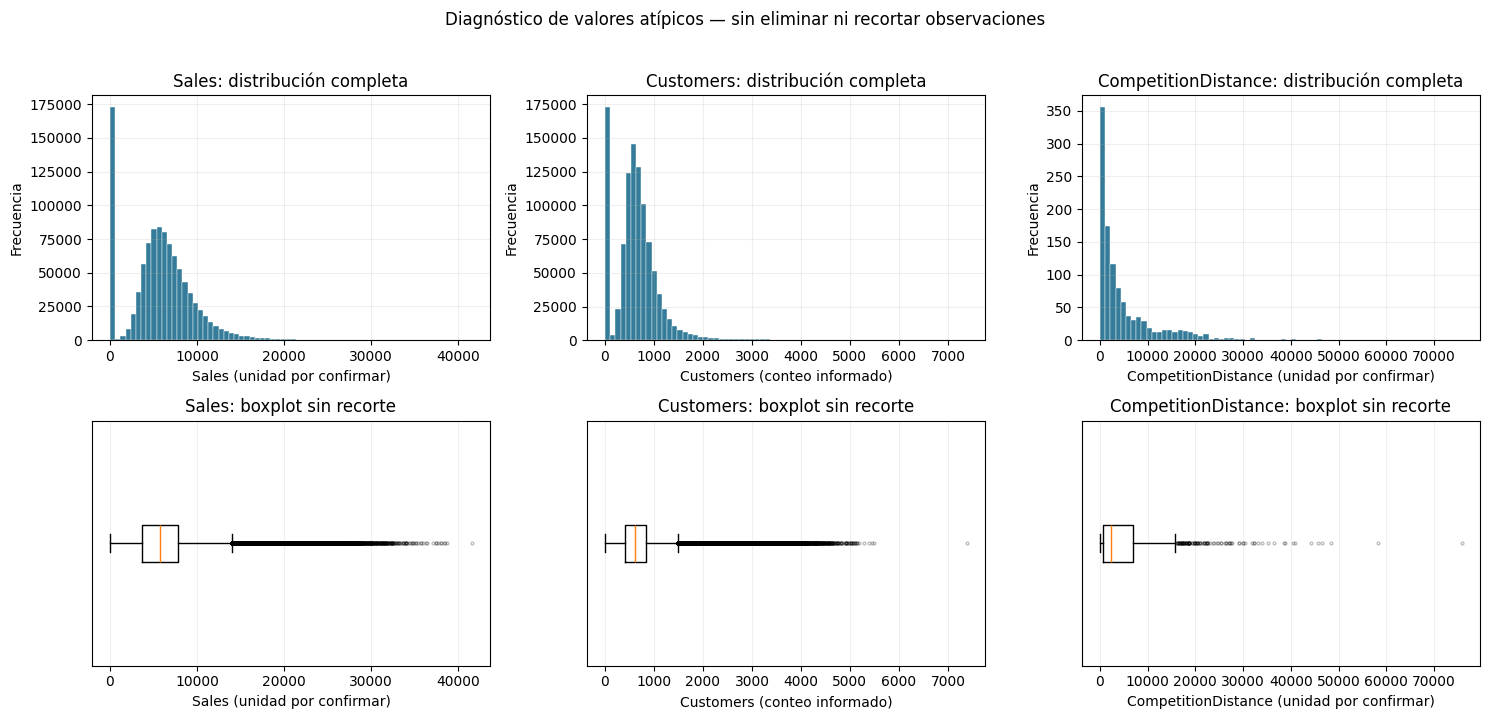

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for idx, (col, series) in enumerate([
    ('Sales', train['Sales']), ('Customers', train['Customers']),
    ('CompetitionDistance', store['CompetitionDistance'])
]):
    # La selección de no nulos es exclusiva del trazado; no modifica la tabla.
    values = series.loc[series.notna()].to_numpy()
    axes[0, idx].hist(values, bins=70, color='#347c99', edgecolor='white', linewidth=.3)
    unit = 'conteo informado' if col == 'Customers' else 'unidad por confirmar'
    axis_label = f'{col} ({unit})'
    axes[0, idx].set(title=f'{col}: distribución completa', xlabel=axis_label, ylabel='Frecuencia')
    axes[1, idx].boxplot(values, vert=False, showfliers=True,
                         flierprops={'markersize': 2, 'alpha': .25})
    axes[1, idx].set(title=f'{col}: boxplot sin recorte', xlabel=axis_label, yticks=[])
fig.suptitle('Diagnóstico de valores atípicos — sin eliminar ni recortar observaciones', y=1.02)
fig.tight_layout()
plt.show()
plt.close(fig)

**Lectura visual.** Las tres variables tienen asimetría a la derecha y valores
altos observables. Las figuras usan el rango completo; las marcas del boxplot
son candidatos estadísticos. No constituyen evidencia suficiente para truncar,
transformar o descartar ventas, clientes o distancias.

### 8.2. Contexto comercial de extremos: tienda, promoción, día y feriado

In [24]:
print('Mayores ventas: registros originales')
display(train.nlargest(12, 'Sales'))
print('Mayor cantidad de clientes: registros originales')
display(train.nlargest(8, 'Customers'))
print('Distancias de competencia más altas: tiendas originales')
display(store.nlargest(8, 'CompetitionDistance'))

Mayores ventas: registros originales


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
44393,909,1,2015-06-22,41551,1721,1,0,0,0
132946,262,5,2015-04-03,38722,5132,1,1,b,0
101726,262,5,2015-05-01,38484,5458,1,1,a,0
87231,262,4,2015-05-14,38367,5192,1,0,a,1
424086,57,1,2014-06-16,38037,1970,1,1,0,0
627776,817,1,2013-12-16,38025,4381,1,1,0,0
627220,261,1,2013-12-16,37646,1964,1,1,0,0
444361,262,4,2014-05-29,37403,5297,1,0,a,0
620531,262,7,2013-12-22,37376,4916,1,0,0,0
245945,262,7,2014-12-21,37122,4962,1,0,0,0


Mayor cantidad de clientes: registros originales


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
993496,817,2,2013-01-22,27190,7388,1,1,0,0
319810,262,5,2014-10-03,35702,5494,1,1,a,0
101726,262,5,2015-05-01,38484,5458,1,1,a,0
432096,262,1,2014-06-09,34692,5387,1,0,a,0
444361,262,4,2014-05-29,37403,5297,1,0,a,0
87231,262,4,2015-05-14,38367,5192,1,0,a,1
129601,262,1,2015-04-06,33655,5152,1,0,b,0
745411,262,7,2013-09-01,32926,5145,1,0,0,0


Distancias de competencia más altas: tiendas originales


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
452,453,a,c,75860.0,NaN,NaN,0,NaN,NaN,NaN
121,122,a,c,58260.0,4.0,2013.0,0,NaN,NaN,NaN
800,801,d,a,48330.0,4.0,2013.0,0,NaN,NaN,NaN
109,110,a,c,46590.0,4.0,2013.0,0,NaN,NaN,NaN
746,747,c,c,45740.0,8.0,2008.0,0,NaN,NaN,NaN
461,462,a,a,44320.0,8.0,2008.0,0,NaN,NaN,NaN
523,524,a,c,40860.0,9.0,2013.0,0,NaN,NaN,NaN
725,726,a,c,40540.0,2.0,2002.0,0,NaN,NaN,NaN


**Interpretación de ejemplos extremos.** La mayor venta es **41.551** (Store **909**,
2015-06-22, lunes, `Promo = 0`, sin feriado codificado). Por eso no todos los picos
pueden atribuirse a promoción. Store **262** aparece reiteradamente entre las
mayores ventas y clientes, incluso en feriados y domingos. El máximo de clientes
es **7.388** en Store **817**, 2013-01-22, con promoción: requiere contraste con
esa tienda y el origen del registro.

La distancia máxima es **75.860**, Store **453**. Puede corresponder a una ubicación
aislada, aunque se deben confirmar unidades y origen antes de decidir su tratamiento.

In [25]:
# Banderas de diagnóstico; no se agregan a train ni se definen como target.
sales_iqr_upper = outlier_summary.loc[
    outlier_summary['variable'].eq('Sales') & outlier_summary['poblacion'].eq('todas_train'),
    'limite_superior'].iloc[0]
customers_iqr_upper = outlier_summary.loc[
    outlier_summary['variable'].eq('Customers') & outlier_summary['poblacion'].eq('todas_train'),
    'limite_superior'].iloc[0]
sales_above_iqr = train['Sales'].gt(sales_iqr_upper)
customers_above_iqr = train['Customers'].gt(customers_iqr_upper)
display(pd.crosstab(sales_above_iqr, customers_above_iqr,
                    rownames=['Sales_sobre_IQR'], colnames=['Customers_sobre_IQR'], margins=True))

def extreme_context(mask, category):
    # Agregar una máscara por categoría cuenta también ceros legítimos del conteo.
    result = mask.groupby(train[category], dropna=False).agg(['size', 'sum', 'mean'])
    result.columns = ['filas_base', 'filas_marcadas', 'fraccion_marcadas']
    result['tasa_marcadas_pct'] = result['fraccion_marcadas'] * 100
    result['participacion_base_pct'] = result['filas_base'] / len(train) * 100
    result['participacion_marcadas_pct'] = result['filas_marcadas'] / int(mask.sum()) * 100
    return result[['filas_base', 'filas_marcadas', 'tasa_marcadas_pct',
                   'participacion_base_pct', 'participacion_marcadas_pct']]

for label, mask in [('Sales', sales_above_iqr), ('Customers', customers_above_iqr)]:
    for col in ['Promo', 'DayOfWeek', 'StateHoliday', 'SchoolHoliday']:
        print(f'Extremos de {label} por {col}; tasas dentro de cada categoría')
        display(extreme_context(mask, col))

Customers_sobre_IQR,False,True,All
Sales_sobre_IQR,,,
False,971403,19112,990515
True,7711,18983,26694
All,979114,38095,1017209


Extremos de Sales por Promo; tasas dentro de cada categoría


,filas_base,filas_marcadas,tasa_marcadas_pct,participacion_base_pct,participacion_marcadas_pct
Promo,,,,,
0,629129,7507,1.193237,61.848548,28.122425
1,388080,19187,4.944084,38.151452,71.877575


Extremos de Sales por DayOfWeek; tasas dentro de cada categoría


,filas_base,filas_marcadas,tasa_marcadas_pct,participacion_base_pct,participacion_marcadas_pct
DayOfWeek,,,,,
1,144730,9449,6.528709,14.228148,35.397468
2,145664,4623,3.173742,14.319968,17.318499
3,145665,3163,2.171421,14.320066,11.849105
4,145845,3044,2.087147,14.337761,11.403312
5,145845,3330,2.283246,14.337761,12.474713
6,144730,2553,1.763974,14.228148,9.563947
7,144730,532,0.367581,14.228148,1.992957


...

,filas_base,filas_marcadas,tasa_marcadas_pct,participacion_base_pct,participacion_marcadas_pct
DayOfWeek,,,,,
1,144730,8538,5.899261,14.228148,22.412390
2,145664,6432,4.415641,14.319968,16.884106
3,145665,5404,3.709882,14.320066,14.185589
4,145845,5478,3.756042,14.337761,14.379840
5,145845,5781,3.963797,14.337761,15.175220
6,144730,4972,3.435362,14.228148,13.051582
7,144730,1490,1.029503,14.228148,3.911274


Extremos de Customers por StateHoliday; tasas dentro de cada categoría


,filas_base,filas_marcadas,tasa_marcadas_pct,participacion_base_pct,participacion_marcadas_pct
StateHoliday,,,,,
0,986159,37780,3.831025,96.947530,99.173120
a,20260,206,1.016782,1.991724,0.540753
b,6690,77,1.150972,0.657682,0.202126
c,4100,32,0.780488,0.403064,0.084001


Extremos de Customers por SchoolHoliday; tasas dentro de cada categoría


,filas_base,filas_marcadas,tasa_marcadas_pct,participacion_base_pct,participacion_marcadas_pct
SchoolHoliday,,,,,
0,835488,30041,3.595623,82.135333,78.858118
1,181721,8054,4.432069,17.864667,21.141882


**Contexto de promoción y calendario.** La tasa de ventas sobre la cerca global
es **4,94 % con Promo = 1** y **1,19 % con Promo = 0**; el lunes alcanza **6,53 %**.
Estas tasas incluyen cierres y poblaciones diferentes. Se muestran tasas dentro
de cada categoría y pesos base para distinguir composición de propensión a extremos.

Promoción, día de la semana y feriados aportan contexto compatible con actividad
real; las asociaciones no establecen causalidad ni validan cada registro. No se
investiga aquí el efecto comercial de las promociones, reservado al EDA posterior.

In [26]:
store_extremes = train.groupby('Store').agg(
    filas=('Sales', 'size'), Sales_mediana=('Sales', 'median'),
    Sales_p99=('Sales', lambda s: s.quantile(.99)), Sales_max=('Sales', 'max'),
    Customers_mediana=('Customers', 'median'), Customers_max=('Customers', 'max'))
store_extremes['Sales_sobre_IQR'] = sales_above_iqr.groupby(train['Store']).sum()
store_extremes['Customers_sobre_IQR'] = customers_above_iqr.groupby(train['Store']).sum()
store_extremes['tasa_Sales_sobre_IQR_pct'] = (
    store_extremes['Sales_sobre_IQR'].div(store_extremes['filas']).mul(100))
display(store_extremes.sort_values('Sales_sobre_IQR', ascending=False).head(12))
display(store_extremes.sort_values('Customers_sobre_IQR', ascending=False).head(8))
print('Contraste de las tiendas con los máximos observados:')
display(store_extremes.loc[[909, 262, 817]])
display(store.loc[store['Store'].isin([909, 262, 817])])

,filas,Sales_mediana,Sales_p99,Sales_max,Customers_mediana,Customers_max,Sales_sobre_IQR,Customers_sobre_IQR,tasa_Sales_sobre_IQR_pct
Store,,,,,,,,,
262,942,19415.5,35479.37,38722,3239.0,5494,939,942,99.681529
562,942,18029.5,26218.08,28680,3127.0,4099,846,942,89.808917
1114,942,19556.5,30240.85,35697,3086.0,4911,773,780,82.059448
251,942,17640.0,29647.02,35350,2320.0,4635,765,775,81.210191
788,942,16549.0,26102.57,32170,1652.5,2643,740,645,78.556263
817,942,20914.0,32023.13,38025,3069.5,7388,738,780,78.343949
513,942,17032.0,26637.31,31094,2008.5,3302,725,778,76.963907
383,942,16454.5,24883.64,28426,2127.5,3127,692,775,73.460722
733,942,14795.5,19657.90,22137,3393.0,4645,625,940,66.348195


,filas,Sales_mediana,Sales_p99,Sales_max,Customers_mediana,Customers_max,Sales_sobre_IQR,Customers_sobre_IQR,tasa_Sales_sobre_IQR_pct
Store,,,,,,,,,
562,942,18029.5,26218.08,28680,3127.0,4099,846,942,89.808917
262,942,19415.5,35479.37,38722,3239.0,5494,939,942,99.681529
733,942,14795.5,19657.90,22137,3393.0,4645,625,940,66.348195
769,942,10732.0,15435.04,18177,3079.0,4582,51,938,5.414013
1097,942,9603.0,15266.75,17039,2460.0,3804,24,936,2.547771
259,942,11419.0,18714.02,21407,2414.5,3648,142,917,15.074310
423,942,10484.0,17047.06,18574,1850.0,3021,87,858,9.235669
335,942,12442.0,25357.95,31406,2509.5,3929,371,844,39.384289


Contraste de las tiendas con los máximos observados:


,filas,Sales_mediana,Sales_p99,Sales_max,Customers_mediana,Customers_max,Sales_sobre_IQR,Customers_sobre_IQR,tasa_Sales_sobre_IQR_pct
Store,,,,,,,,,
909,758,8889.5,18574.71,41551,927.0,1767,88,11,11.609499
262,942,19415.5,35479.37,38722,3239.0,5494,939,942,99.681529
817,942,20914.0,32023.13,38025,3069.5,7388,738,780,78.343949


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
261,262,b,a,1180.0,5.0,2013.0,0,NaN,NaN,NaN
816,817,a,a,140.0,3.0,2006.0,0,NaN,NaN,NaN
908,909,a,c,1680.0,NaN,NaN,1,45.0,2009.0,"Feb,May,Aug,Nov"


**Heterogeneidad entre tiendas.** Store **262** supera la cerca global de ventas
en **939 de 942 días (99,68 %)**. Ese umbral marcaría casi toda su actividad habitual;
la recurrencia apunta a diferencias persistentes de volumen, sin demostrar errores.
En Store **909**, la venta máxima de **41.551** supera ampliamente su propio
percentil 99 (**18.574,71**), de modo que merece revisión individual.

La evidencia exige distinguir heterogeneidad comercial de picos aislados antes
de proponer una transformación. Estos percentiles son diagnósticos; no se elige
un umbral de ventas altas para Machine Learning ni se elimina ningún caso.

### 8.3. Registro de anomalías y situaciones para seguimiento

| Observación | Evidencia | Lectura prudente |
|---|---|---|
| Abierta sin ventas | 54 filas en 41 tiendas; 2 también con clientes | Inconsistencia potencial o día comercial sin venta; consultar origen. |
| Cobertura histórica incompleta | 180 tiendas ausentes en 2014-07 a 2014-12; Store 988 sin 2013-01-01 | Ausencia de registros, no ceros observados. |
| Apertura desconocida en test | 11 filas de Store 622 | Falta de información confirmada; no asumir apertura. |
| Competencia con año 1900 | Store 815 | Posible valor histórico o código especial; no reemplazar. |
| Competencia después de train | 3 tiendas, agosto de 2015 | Metadato estático con alcance temporal distinto. |
| Valores numéricos extremos | Ventas 41.551; clientes 7.388; distancia 75.860 | Señales estadísticas, pendientes de validación comercial. |
| Promo2 sin detalles | 544 tiendas no participantes | Faltantes compatibles con «no aplica», sin contradicciones observadas. |

Las poblaciones pueden solaparse. Esta tabla no es una lista de filas a eliminar.

## 9. Conclusiones de auditoría

1. **Integridad de claves:** train y store admiten la relación N:1 por `Store`.
   No hay duplicados completos ni duplicados de la clave candidata en train, ni
   claves de tienda duplicadas en store. El join conserva las filas originales.
2. **Completitud distinta según nivel:** train no tiene nulos de celda, pero sí
   huecos de cobertura. Store tiene faltantes de metadatos y test tiene 11 `Open`
   desconocidos. Son problemas diferentes y no deben recibir una solución única.
3. **Coherencia comercial:** los cierres no tienen ventas/clientes positivos;
   las 54 filas abiertas sin ventas necesitan revisión. Promociones durante
   cierres y aperturas en feriados/domingo pueden ser comportamientos válidos.
4. **Metadatos:** los nulos de Promo2 son consistentes con no participación.
   Los nulos de competencia no permiten la misma conclusión. Las fechas de
   inicio de atributos deben respetarse cuando se estudie su significado histórico.
5. **Extremos:** las distribuciones y contextos señalan casos para revisar,
   sin demostrar errores ni justificar eliminación, imputación o recorte.

Las conclusiones corresponden a los cuatro CSV identificados por sus hashes al
inicio. Si cambia la fuente, se debe volver a ejecutar y revisar también el texto
interpretativo. Las tablas muestran todo el conjunto cuando se cuentan casos;
`head`/`nlargest` solo acotan los ejemplos visibles.

## 10. Decisiones pendientes de limpieza

Estas decisiones **no se ejecutan en esta fase**. Cada propuesta debe conservar
su evidencia y alternativa de mantener el dato original hasta resolver su significado,
como exige AGENTS.md. El dataset limpio previsto en requirements.md se pospone
por el alcance explícito de esta solicitud.

| Tema | Evidencia o consulta necesaria | Decisión pendiente |
|---|---|---|
| Cobertura tienda–fecha | Motivo de ausencia de las 180 tiendas y de Store 988 | Determinar si se acepta la cobertura o se solicita una nueva extracción; no completar con cero por defecto. |
| Abierta sin ventas / clientes sin ventas | Registro fuente de las 54 filas, especialmente los 2 casos con clientes | Distinguir situación comercial válida de un problema de captura. |
| `Open` de test | Calendario de apertura de Store 622 | Definir un tratamiento posterior con evidencia. |
| Promo2 | Diccionario de participación y campos asociados | Formalizar «no aplica» frente a «desconocido», sin inventar inicios de promoción. |
| Competencia faltante | Confirmación de existencia del competidor, fechas y distancia | Determinar qué nulos son desconocidos y si alguno es estructural. |
| Año 1900 y fechas posteriores | Convención de códigos de origen y fecha del snapshot de store | Confirmar plausibilidad y alcance temporal de los atributos. |
| Extremos numéricos | Unidades, registros fuente y contexto de cada tienda | Conservar valores comerciales reales y justificar cualquier tratamiento futuro. |
| Categorías y fechas | Diccionario de datos, códigos y convención de semanas | Decidir tipos y representación en una fase posterior; ahora se conservan como se leyeron. |

La definición de un target, la creación de variables, la estrategia de evaluación
y cualquier dataset processed quedan fuera de esta auditoría.

### Control final de preservación

Se verifica que los bytes de los cuatro CSV y los valores, orden y tipos de las
tablas cargadas coincidan con el inicio. También se compara el inventario de
`data/processed` para confirmar que esta fase no lo modificó.

In [27]:
raw_hashes_after = {name: file_sha256(RAW / name) for name in FILES}
frame_hashes_after = {name: frame_fingerprint(df) for name, df in datasets.items()}
preservation = pd.DataFrame([
    {'dataset': name, 'CSV_sin_cambios': raw_hashes_before[file] == raw_hashes_after[file],
     'DataFrame_sin_cambios': frame_hashes_before[name] == frame_hashes_after[name]}
    for name, file in zip(datasets, FILES)
])
display(preservation)
assert raw_hashes_before == raw_hashes_after, 'Se alteraron los archivos originales'
assert frame_hashes_before == frame_hashes_after, 'Se alteró una tabla original en memoria'
assert processed_before == inventory(PROCESSED), 'Cambió el contenido de data/processed'
assert instruction_hashes_before == {name: file_sha256(ROOT / name) for name in INSTRUCTIONS}, \
    'Cambió la documentación de referencia durante la ejecución'
print('Documentación de referencia: AGENTS.md, requirements.md y README.md sin cambios.')
print('Control satisfactorio: CSV originales y DataFrames intactos; data/processed sin cambios.')
print('Fin de Fase 1. No se aplicaron decisiones de limpieza, EDA posterior ni Machine Learning.')

,dataset,CSV_sin_cambios,DataFrame_sin_cambios
0,train,True,True
1,store,True,True
2,test,True,True
3,sample_submission,True,True


Documentación de referencia: AGENTS.md, requirements.md y README.md sin cambios.
Control satisfactorio: CSV originales y DataFrames intactos; data/processed sin cambios.
Fin de Fase 1. No se aplicaron decisiones de limpieza, EDA posterior ni Machine Learning.


## Hallazgos y decisiones pendientes

**Problemas confirmados**

- Faltan metadatos de competencia: distancia en 3 tiendas y mes/año en 354.
- `Open` no está informado en 11 filas de test, todas de Store 622.
- Faltan 33.121 pares tienda–fecha frente a una referencia rectangular; el hecho
  está confirmado, pero su condición de error de origen depende de la cobertura esperada.

**Comportamientos posiblemente válidos**

- Ventas y clientes cero con tienda cerrada.
- Promoción informada con tienda cerrada (11.184 filas).
- Apertura en feriado codificado (910 filas) o domingo (3.593).
- Ventas, clientes o distancias altas asociadas con diferencias reales entre tiendas.
- Fechas de apertura de competencia posteriores al período histórico de train.

**Missing values estructurales**

- Los tres campos de detalle de Promo2 faltan en las 544 tiendas con `Promo2 = 0`
  y están completos en las 571 participantes. Es evidencia fuerte de faltantes
  estructurales, pendiente de confirmación semántica del diccionario.
- No se puede confirmar esa explicación para los campos de competencia.

**Anomalías que requieren análisis**

- 54 filas con `Open = 1` y `Sales = 0`; incluyen los 2 casos con clientes positivos.
- Competencia desde 1900 en Store 815; contraste de fechas y códigos de origen.
- Bloque de ausencia de 180 tiendas y el día faltante de Store 988.
- Picos de ventas/clientes y cola de distancias: revisar casos con su contexto comercial.

**Decisiones de limpieza todavía pendientes**

- Confirmar el diccionario, unidades, códigos y cobertura prevista con el origen.
- Resolver semántica de faltantes de Promo2 y competencia antes de elegir cualquier tratamiento.
- Verificar registros sin ventas, `Open` desconocido y fechas/extremos señalados.
- Justificar por separado cualquier decisión futura sobre tipos, faltantes y anomalías.

**No se ejecutó ninguna de estas decisiones. La Fase 1 termina aquí.**

## 11. Limpieza controlada

### Fase 1B — Aplicación de decisiones aprobadas

Las secciones anteriores son la **auditoría aprobada (Fase 1A)** y se conservan como
antecedente, con sus resultados originales. Los asuntos que allí quedaron pendientes
se resuelven para esta entrega mediante las siguientes decisiones explícitas del
usuario. **No se repite ni reejecuta la auditoría.** Esta sección y las siguientes
pueden ejecutarse desde un kernel nuevo, sin ejecutar las secciones 1–10.

Se releen AGENTS.md, requirements.md y el contexto de README.md. Se continúa la
metodología desde **decidir → transformar → validar**; las transformaciones se
limitan a tipos e integración de tablas, sin imputaciones ni cambios comerciales.

| Tema | Decisión aprobada y aplicada |
|---|---|
| Cobertura histórica | Conservar exclusivamente las filas originales de train. No crear los 33.121 pares ausentes ni asignarles ventas, clientes o apertura cero. |
| Abiertas sin ventas | Conservar las 54 filas, incluidos los 2 registros con clientes positivos. Son anomalías conocidas sin evidencia para corregir Sales, Customers u Open. |
| Outliers | Conservar todos los valores de Sales, Customers y CompetitionDistance: no eliminar, recortar ni winsorizar. |
| Promo2 | Los detalles ausentes cuando Promo2 = 0 significan conceptualmente «no aplica». Mantenerlos como missing/NaN, sin semanas, años o intervalos ficticios. |
| Competencia | Los faltantes son desconocidos y se conservan. Mantener también CompetitionOpenSinceYear = 1900 y cualquier otro valor observado. |
| Test de Kaggle | No incorporar test ni sample_submission al clean; no generar un test procesado. La aclaración sobre Open se documenta abajo. |
| Tipos | Convertir Date a datetime con validación estricta; representar las categorías nominales como category, conservando sus códigos. |
| Join | Left join train N:1 store por Store con validate="many_to_one", sin perder o multiplicar observaciones. |
| Entrega | Guardar solo las 18 columnas originales integradas, sin índice exportado, target ni features de ML, en data/processed/rossmann_clean.csv. |

**Aclaración sobre test.csv.** El organizador FlorianKnauer, identificado como
Competition Host, confirmó en el foro de Kaggle que los **11 Open faltantes de
Store 622 corresponden a Open = 0**. Esto actualiza la interpretación que quedó
pendiente en la auditoría. Se documenta la aclaración y se conservan los archivos
raw; no se procesa test en esta fase. Fuente: [Kaggle — Putting stores on the map,
aclaración del organizador](https://www.kaggle.com/competitions/rossmann-store-sales/discussion/17048),
consultada el 16 de octubre de 2026.

El clean es una base histórica integrada para análisis. Conservar Sales y Customers
no autoriza utilizarlas como features predictivas: esa selección queda para una
fase posterior y deberá cumplir las reglas de prevención de leakage de AGENTS.md.

In [28]:
# Inicio autocontenido de la Fase 1B: cargar únicamente las dos tablas del clean.
from pathlib import Path
import hashlib
import pandas as pd
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 170)

clean_root = next(p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / 'data' / 'raw' / 'train.csv').is_file())
clean_raw = clean_root / 'data' / 'raw'
clean_output = clean_root / 'data' / 'processed' / 'rossmann_clean.csv'

def clean_file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

clean_raw_files = ['train.csv', 'store.csv', 'test.csv', 'sample_submission.csv']
clean_raw_before = {name: clean_file_sha256(clean_raw / name) for name in clean_raw_files}
clean_documents = ['AGENTS.md', 'requirements.md', 'README.md']
clean_docs_before = {name: clean_file_sha256(clean_root / name) for name in clean_documents}
clean_other_processed_before = {
    str(p.relative_to(clean_output.parent)): clean_file_sha256(p)
    for p in clean_output.parent.rglob('*') if p.is_file() and p != clean_output
}

# Leer los códigos nominales como texto evita mezclar el código '0' con enteros.
# No se reemplaza ninguna etiqueta ni se asignan valores a los faltantes.
source_train = pd.read_csv(clean_raw / 'train.csv', low_memory=False,
                           dtype={'StateHoliday': 'string'})
source_store = pd.read_csv(clean_raw / 'store.csv', low_memory=False,
                           dtype={'StoreType': 'string', 'Assortment': 'string',
                                  'PromoInterval': 'string'})

with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame([{'archivo_raw': name, 'sha256': checksum}
                          for name, checksum in clean_raw_before.items()]))
print('Fuentes del clean: train.csv + store.csv. Test y sample_submission no se cargan en esta fase.')

,archivo_raw,sha256
0,train.csv,f6e4597c142d7d909a13d53b68a8e85c00b9a4c7b5ff40adbb37d6829cc1f4cc
1,store.csv,f56bd124a2849489e6bbb5c000f5fc9640204355e316475c918ae4d089afb344
2,test.csv,e75f79972de046d88c2fd55da19df627f5ca654aaf418090d4d30c60ea7dbe26
3,sample_submission.csv,592d892eb07072ddfa3773f13c4822ce5d01981243134c8d512ae30f016805db


Fuentes del clean: train.csv + store.csv. Test y sample_submission no se cargan en esta fase.


### 11.1. Integración controlada

Se comprueba la unicidad y ausencia de nulos de Store en la dimensión inmediatamente
antes del join. El indicador de correspondencia se utiliza solo para validación y
no se incorpora al esquema final. Se conserva el orden original de train.

In [29]:
assert source_store['Store'].notna().all(), 'La dimensión contiene Store nulo'
assert source_store['Store'].is_unique, 'Store no es único en la dimensión'
assert source_train[['Store', 'Date']].notna().all().all()
assert not source_train.duplicated(['Store', 'Date']).any()

clean_expected_columns = list(source_train.columns) + [
    col for col in source_store.columns if col != 'Store'
]
clean_join = source_train.merge(source_store, on='Store', how='left',
                                validate='many_to_one', indicator=True, sort=False)
clean_unmatched = clean_join['_merge'].eq('left_only')
clean_join_summary = pd.DataFrame([{
    'relacion_validada': 'many_to_one',
    'Store_unico_en_store': source_store['Store'].is_unique,
    'filas_train': len(source_train), 'filas_join': len(clean_join),
    'diferencia_filas': len(clean_join) - len(source_train),
    'filas_sin_match': int(clean_unmatched.sum()),
    'tiendas_sin_match': clean_join.loc[clean_unmatched, 'Store'].nunique(),
    'duplicados_Store_Date_antes': int(source_train.duplicated(['Store', 'Date']).sum()),
    'duplicados_Store_Date_despues': int(clean_join.duplicated(['Store', 'Date']).sum())
}])
display(clean_join_summary)
print('Store sin correspondencia:', sorted(set(clean_join.loc[clean_unmatched, 'Store'])))
assert len(clean_join) == len(source_train)
assert not clean_unmatched.any()
assert not clean_join.duplicated(['Store', 'Date']).any()
pd.testing.assert_frame_equal(clean_join[source_train.columns], source_train)

# Excluir únicamente el indicador técnico; no se excluye ninguna fila.
rossmann_clean = clean_join.loc[:, clean_expected_columns].copy()
del clean_join

,relacion_validada,Store_unico_en_store,filas_train,filas_join,diferencia_filas,filas_sin_match,tiendas_sin_match,duplicados_Store_Date_antes,duplicados_Store_Date_despues
0,many_to_one,True,1017209,1017209,0,0,0,0,0


Store sin correspondencia: []


**Validación de la integración.** El join N:1 conserva las **1.017.209 filas** y
no introduce tiendas sin correspondencia ni claves Store–Date duplicadas. La
igualdad exacta del lado de train se comprueba antes de convertir tipos. No se
agregó ninguna combinación ausente al histórico y el indicador técnico quedó fuera
del dataset de 18 columnas.

### 11.2. Tipos con semántica explícita

- Date se convierte con el formato `%Y-%m-%d` y `errors="raise"`: una fecha inválida
  detendría el proceso; no se convierte silenciosamente en un faltante.
- StateHoliday, StoreType, Assortment y PromoInterval se representan como
  categorías nominales. Se conservan todas las etiquetas, incluido `'0'` en
  StateHoliday y `Sept` dentro de PromoInterval; no se renombran categorías.
- Store conserva su función de identificador. DayOfWeek sigue siendo un código
  de calendario de 1 a 7, y Open, Promo, SchoolHoliday y Promo2 conservan los
  indicadores enteros 0/1. Esos códigos no se tratan como magnitudes continuas.
- Las medidas y campos de calendario de store mantienen sus valores y faltantes.
  Los campos numéricos con nulos pueden seguir representados como float64;
  no se imputa ni cambia un mes, semana o año por decidir un tipo.

Estas representaciones no son one-hot encoding, scaling ni encoding para un modelo.

In [30]:
rossmann_clean['Date'] = pd.to_datetime(rossmann_clean['Date'],
                                      format='%Y-%m-%d', errors='raise')
clean_category_columns = ['StateHoliday', 'StoreType', 'Assortment', 'PromoInterval']
for col in clean_category_columns:
    rossmann_clean[col] = rossmann_clean[col].astype('category')

display(pd.DataFrame({'tipo_clean_en_memoria': rossmann_clean.dtypes.astype(str)}))
print('Columnas finales:', list(rossmann_clean.columns))

,tipo_clean_en_memoria
Store,int64
DayOfWeek,int64
Date,datetime64[us]
Sales,int64
Customers,int64
Open,int64
Promo,int64
StateHoliday,category
SchoolHoliday,int64
StoreType,category


Columnas finales: ['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


## 12. Validación del dataset limpio

Los siguientes controles validan la transformación aprobada; no vuelven a explorar
los datos ni recalculan los análisis de la auditoría. Se comprueba el esquema,
los tipos, la conservación íntegra de observaciones y valores, y la procedencia
de cada faltante antes de exportar y tras volver a leer el CSV.

### 12.1. Observaciones, tipos y valores conservados

In [31]:
assert list(rossmann_clean.columns) == clean_expected_columns
assert rossmann_clean.shape == (len(source_train), len(clean_expected_columns))
assert rossmann_clean['Store'].nunique() == source_train['Store'].nunique()
assert pd.api.types.is_datetime64_any_dtype(rossmann_clean['Date'])
assert not rossmann_clean['Date'].isna().any()
assert not rossmann_clean.duplicated(['Store', 'Date']).any()

# Revertir la representación solo en una copia de validación y comparar TODO train.
# Así se prueba que no cambiaron filas, orden, Sales, Customers, Open ni otros valores.
clean_train_check = rossmann_clean[source_train.columns].copy()
clean_train_check['Date'] = clean_train_check['Date'].dt.strftime('%Y-%m-%d')
clean_train_check['Date'] = clean_train_check['Date'].astype(source_train['Date'].dtype)
clean_train_check['StateHoliday'] = clean_train_check['StateHoliday'].astype(source_train['StateHoliday'].dtype)
pd.testing.assert_frame_equal(clean_train_check, source_train, check_exact=True)
del clean_train_check

# Verificar todos los atributos contra store, no solamente sus máximos o conteos.
clean_store_lookup = source_store.set_index('Store')
for col in source_store.columns:
    if col == 'Store':
        continue
    expected = source_train['Store'].map(clean_store_lookup[col])
    observed = rossmann_clean[col].astype(expected.dtype)
    pd.testing.assert_series_equal(observed, expected, check_names=False, check_exact=True)

clean_original_anomalies = source_train['Open'].eq(1) & source_train['Sales'].eq(0)
clean_retained_anomalies = rossmann_clean['Open'].eq(1) & rossmann_clean['Sales'].eq(0)
clean_retained_with_customers = clean_retained_anomalies & rossmann_clean['Customers'].gt(0)
assert int(clean_original_anomalies.sum()) == int(clean_retained_anomalies.sum()) == 54
assert int(clean_retained_with_customers.sum()) == 2

# Coherencia de los códigos conservados; no se recodifica ningún valor.
for col in ['Open', 'Promo', 'SchoolHoliday', 'Promo2']:
    assert rossmann_clean[col].isin([0, 1]).all()
assert rossmann_clean['DayOfWeek'].isin(range(1, 8)).all()
assert rossmann_clean['Date'].dt.dayofweek.add(1).eq(rossmann_clean['DayOfWeek']).all()
assert not (rossmann_clean['Open'].eq(0) & rossmann_clean['Sales'].gt(0)).any()
assert not (rossmann_clean['Open'].eq(0) & rossmann_clean['Customers'].gt(0)).any()
assert not (rossmann_clean['Sales'].gt(0) & rossmann_clean['Customers'].eq(0)).any()

clean_validation_summary = pd.DataFrame([{
    'filas': len(rossmann_clean), 'columnas': rossmann_clean.shape[1],
    'tiendas': rossmann_clean['Store'].nunique(),
    'fecha_min': rossmann_clean['Date'].min(), 'fecha_max': rossmann_clean['Date'].max(),
    'duplicados_Store_Date': int(rossmann_clean.duplicated(['Store', 'Date']).sum()),
    'duplicados_completos': int(rossmann_clean.duplicated().sum()),
    'diferencia_filas_vs_train': len(rossmann_clean) - len(source_train),
    'abiertas_sin_ventas_conservadas': int(clean_retained_anomalies.sum()),
    'de_ellas_con_clientes': int(clean_retained_with_customers.sum()),
    'filas_con_año_competencia_1900': int(rossmann_clean['CompetitionOpenSinceYear'].eq(1900).sum())
}])
display(clean_validation_summary.T.rename(columns={0: 'resultado'}))
print('Todos los valores de train y los atributos incorporados desde store coinciden exactamente con el origen.')

,resultado
filas,1017209
columnas,18
tiendas,1115
fecha_min,2013-01-01 00:00:00
fecha_max,2015-07-31 00:00:00
duplicados_Store_Date,0
duplicados_completos,0
diferencia_filas_vs_train,0
abiertas_sin_ventas_conservadas,54
de_ellas_con_clientes,2


Todos los valores de train y los atributos incorporados desde store coinciden exactamente con el origen.


**Resultado de los controles.** El clean contiene **1.017.209 filas, 18 columnas y
1.115 tiendas**, desde **2013-01-01 hasta 2015-07-31**, sin duplicados de la clave.
La comparación íntegra de las columnas originales demuestra que no se añadieron
filas sintéticas, eliminaron registros o alteraron ventas, clientes, apertura ni
extremos. También se comparan todos los atributos de store, incluidos sus valores
altos y el año 1900. Las **54 anomalías conocidas y sus 2 casos con clientes** se
conservan, sin asumir una corrección por ausencia de evidencia.

### 12.2. Missing estructural frente a missing desconocido

**Estructural («no aplica»):** los tres detalles de Promo2 cuando Promo2 = 0.
**Desconocido:** distancia o fecha de competencia ausentes; no se interpretan como
ausencia de competidor. Ambos permanecen missing en el archivo, con distinta
semántica documentada, sin añadir columnas derivadas al dataset.

In [32]:
clean_missing = pd.DataFrame({'missing': rossmann_clean.isna().sum(),
                             'porcentaje': rossmann_clean.isna().mean() * 100})
display(clean_missing)

clean_promo2_columns = ['Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']
clean_competition_columns = ['CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear']
assert rossmann_clean.loc[rossmann_clean['Promo2'].eq(0), clean_promo2_columns].isna().all().all()
assert rossmann_clean.loc[rossmann_clean['Promo2'].eq(1), clean_promo2_columns].notna().all().all()

clean_missing_records = []
for col in clean_competition_columns + clean_promo2_columns:
    expected = source_train['Store'].map(clean_store_lookup[col])
    missing = rossmann_clean[col].isna()
    structural = missing & rossmann_clean['Promo2'].eq(0) if col in clean_promo2_columns else pd.Series(False, index=rossmann_clean.index)
    unknown = missing & ~structural
    clean_missing_records.append({
        'variable': col, 'tiendas_missing_origen': int(source_store[col].isna().sum()),
        'filas_missing_esperadas': int(expected.isna().sum()),
        'filas_missing_clean': int(missing.sum()),
        'missing_estructural_no_aplica': int(structural.sum()),
        'missing_desconocido': int(unknown.sum()),
        'missing_adicional_por_join': int(missing.sum()) - int(expected.isna().sum())
    })
clean_missing_semantics = pd.DataFrame(clean_missing_records).set_index('variable')
display(clean_missing_semantics)
assert clean_missing_semantics['missing_adicional_por_join'].eq(0).all()
assert clean_missing_semantics['filas_missing_clean'].eq(
    clean_missing_semantics['missing_estructural_no_aplica'] + clean_missing_semantics['missing_desconocido']).all()

,missing,porcentaje
Store,0,0.000000
DayOfWeek,0,0.000000
Date,0,0.000000
Sales,0,0.000000
Customers,0,0.000000
Open,0,0.000000
Promo,0,0.000000
StateHoliday,0,0.000000
SchoolHoliday,0,0.000000
StoreType,0,0.000000


,tiendas_missing_origen,filas_missing_esperadas,filas_missing_clean,missing_estructural_no_aplica,missing_desconocido,missing_adicional_por_join
variable,,,,,,
CompetitionDistance,3,2642,2642,0,2642,0
CompetitionOpenSinceMonth,354,323348,323348,0,323348,0
CompetitionOpenSinceYear,354,323348,323348,0,323348,0
Promo2SinceWeek,544,508031,508031,508031,0,0
Promo2SinceYear,544,508031,508031,508031,0,0
PromoInterval,544,508031,508031,508031,0,0


**Interpretación.** Cada detalle de Promo2 conserva **508.031 faltantes estructurales**
al repetirse sus tiendas por día. CompetitionDistance conserva **2.642 faltantes
desconocidos**, y el mes y año de apertura de competencia **323.348 cada uno**.
Son conteos de celdas por variable y pueden corresponder a las mismas filas;
no deben sumarse como registros independientes. El join no introduce faltantes
adicionales. Ningún NaN se sustituye por cero u otro valor ficticio.

La imputación que pudiera necesitar un modelo queda para el pipeline de ML,
ajustada solo con su conjunto de entrenamiento. Esta entrega no aprende parámetros
de imputación, escalado, encoding ni un umbral de target.

### 12.3. Exportación y verificación del archivo

Se exportan exclusivamente las columnas de train más los atributos de store,
sin el índice ni el indicador técnico del merge. Los faltantes se serializan como
celdas vacías del CSV y recuperan su condición de missing al leerlo.

In [33]:
clean_output.parent.mkdir(parents=True, exist_ok=True)
rossmann_clean.to_csv(clean_output, index=False, encoding='utf-8',
                      date_format='%Y-%m-%d', na_rep='')
assert clean_output.is_file() and clean_output.stat().st_size > 0

# CSV no conserva tipos pandas. Reponer únicamente los tipos documentados al leerlo.
clean_reloaded = pd.read_csv(clean_output, low_memory=False,
                             dtype={col: 'string' for col in clean_category_columns})
clean_reloaded['Date'] = pd.to_datetime(clean_reloaded['Date'],
                                       format='%Y-%m-%d', errors='raise')
for col in clean_category_columns:
    clean_reloaded[col] = clean_reloaded[col].astype('category')

pd.testing.assert_frame_equal(clean_reloaded, rossmann_clean, check_exact=True)
assert list(clean_reloaded.columns) == clean_expected_columns
assert len(clean_reloaded) == len(source_train)
assert not clean_reloaded.duplicated(['Store', 'Date']).any()
assert clean_reloaded.isna().sum().equals(rossmann_clean.isna().sum())

display(pd.DataFrame([{
    'archivo': str(clean_output.relative_to(clean_root)),
    'existe': clean_output.is_file(), 'bytes': clean_output.stat().st_size,
    'filas_releidas': len(clean_reloaded), 'columnas_releidas': clean_reloaded.shape[1],
    'igualdad_completa_tras_relectura': True,
    'sha256': clean_file_sha256(clean_output)
}]))

,archivo,existe,bytes,filas_releidas,columnas_releidas,igualdad_completa_tras_relectura,sha256
0,data\processed\rossmann_clean.csv,True,73343853,1017209,18,True,02dbaaa1491f9380c148ddc01e8d4eb808ae98da1790cef4576a68bee681d28a


**Archivo validado.** La relectura reproduce exactamente los valores, el orden de
filas, los faltantes y los tipos reconstruidos del DataFrame clean. `Date` es
datetime durante el procesamiento; en CSV se escribe como fecha ISO `YYYY-MM-DD`.
Al consumir el archivo debe parsearse de nuevo como fecha, y las cuatro columnas
nominales deben volver a tiparse como category si se desea esa representación.
El CSV conserva las etiquetas originales, no códigos internos de categorías.

### 12.4. Preservación de fuentes y alcance

In [34]:
clean_raw_after = {name: clean_file_sha256(clean_raw / name) for name in clean_raw_files}
assert clean_raw_before == clean_raw_after, 'Cambió un CSV original'
assert clean_docs_before == {name: clean_file_sha256(clean_root / name) for name in clean_documents}
clean_other_processed_after = {
    str(p.relative_to(clean_output.parent)): clean_file_sha256(p)
    for p in clean_output.parent.rglob('*') if p.is_file() and p != clean_output
}
assert clean_other_processed_before == clean_other_processed_after
display(pd.DataFrame([{'archivo_raw': name, 'sin_cambios': checksum == clean_raw_after[name]}
                      for name, checksum in clean_raw_before.items()]))
print('Fuentes raw y documentos intactos. Único dataset generado: data/processed/rossmann_clean.csv.')
print('Fase 1B completada: integración N:1 y tipos validados; no se ejecutó el EDA ni Machine Learning.')

,archivo_raw,sin_cambios
0,train.csv,True
1,store.csv,True
2,test.csv,True
3,sample_submission.csv,True


Fuentes raw y documentos intactos. Único dataset generado: data/processed/rossmann_clean.csv.
Fase 1B completada: integración N:1 y tipos validados; no se ejecutó el EDA ni Machine Learning.


## 13. Resultado de la Fase 1

**Qué se corrigió o formalizó.** Se convirtió Date a datetime en el procesamiento,
se fijó una representación nominal consistente conservando los códigos y se
integraron train y store mediante una relación N:1 validada. Se formalizó «no aplica»
para los faltantes estructurales de Promo2 y se documentó la aclaración de Kaggle
sobre Open de Store 622. No se encontró evidencia aprobada para corregir valores
comerciales individuales.

**Qué deliberadamente no se corrigió.** Se conservaron todas las observaciones de
train, sin crear las 33.121 combinaciones ausentes; las 54 filas abiertas sin ventas,
incluidos sus 2 registros con clientes; los valores extremos; los faltantes de
Promo2 y competencia; y CompetitionOpenSinceYear = 1900. «Clean» significa aquí
integrado, tipado y validado conforme a las decisiones aprobadas, no libre de nulos
o de anomalías conocidas. Test y sample_submission quedaron fuera del dataset.

**Reservado para EDA.** Evolución de ventas, diferencias entre tiendas y estudio
del comportamiento de promociones, tipos de tienda, surtido y calendario, con sus
conclusiones comerciales. No se modifica ni ejecuta 02_eda_promotions.ipynb.

**Reservado para Machine Learning.** Definición justificada del target, creación
y selección de features disponibles antes de la venta, partición temporal,
imputación dentro del pipeline usando solo entrenamiento, encoding, escalado y
evaluación de modelos. No se crean variables derivadas de Sales ni un dataset de ML.

**Entrega final:** `data/processed/rossmann_clean.csv`, con **1.017.209 filas y 18
columnas**, 1.115 tiendas y fechas entre 2013-01-01 y 2015-07-31. Su existencia y
relectura exacta quedaron verificadas en la sección 12. La Fase 1B termina aquí.